In [33]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import root_mean_squared_error
from sklearn.metrics import r2_score
from sklearn.metrics import mean_squared_error
from xgboost import XGBRegressor
from xgboost import plot_importance
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor


# Load dataset


In [34]:
DATASET_PATH = '..\\' + "ml_dataset.csv"
data = pd.read_csv(DATASET_PATH)

data["delivery_day"] = pd.to_datetime(data["delivery_day"])
data = data.sort_values(["delivery_day", "hour"]).reset_index(drop=True)

    # Convert hourly observations to one row per day. Numeric columns,
    # including price_value, become daily averages.
data = (
        data.groupby("delivery_day", as_index=False)
        .mean(numeric_only=True)
        .sort_values("delivery_day")
        .reset_index(drop=True)
    )

data["target_price_next_day"] = data["price_value"].shift(-1)

data = data.dropna(subset=["target_price_next_day"])   

seasonal_splits = [
    (
        "Lower-volatility 2025 (train: Apr-Jun 2025, test: Jul-Sep 2025)",
        data["delivery_day"].between("2025-07-01", "2025-09-30"),
        data["delivery_day"].between("2025-04-01", "2025-06-30"),
    ),
]


C:\Users\larsm\AppData\Local\Temp\ipykernel_23292\3182709888.py:11: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  .mean(numeric_only=True)


In [35]:
import sys

sys.path.append('..\\')

import feature_sets

In [36]:
feature_columns = feature_sets.FEATURE_SETS["full_set"]

In [37]:
print(feature_columns)

['hour', 'price_value', 'buy_volume_value', 'sell_volume_value', 'net_volume', 'flow_DK1_export', 'flow_DK1_import', 'flow_GER_export', 'flow_GER_import', 'flow_NL_export', 'flow_NL_import', 'flow_NO1_export', 'flow_NO1_import', 'flow_NO5_export', 'flow_NO5_import', 'capacity_GER', 'capacity_NL', 'capacity_NO1', 'capacity_NO5', 'util_GER', 'util_NL', 'util_NO1', 'util_NO5', 'price_DK1', 'price_NO1', 'price_NO5', 'price_NL', 'price_DE_LU', 'price_BE', 'price_FR', 'total_exports', 'total_imports', 'net_flow', 'day_of_week', 'month', 'day_of_year', 'day_sin', 'day_cos', 'year_sin', 'year_cos', 'price_lag_24', 'price_lag_168', 'price_DK1_lag24', 'price_NO1_lag24', 'price_NO5_lag24', 'price_DK1_lag168', 'price_NO1_lag168', 'price_NO5_lag168']


In [38]:
data.head()

,delivery_day,hour,price_value,buy_volume_value,sell_volume_value,net_volume,flow_DK1_export,flow_DK1_import,flow_GER_export,flow_GER_import,...,price_FR_lag168,no_2_forecasted_generation_lag168,no_1_forecasted_generation_lag168,no_5_forecasted_generation_lag168,de_lu_forecasted_generation_lag168,no_2_forecasted_load_lag168,no_1_forecasted_load_lag168,no_5_forecasted_load_lag168,de_lu_forecasted_load_lag168,target_price_next_day
0,2024-10-01,11.5,32.898333,4135.716667,3995.041667,140.675000,243.275000,422.270833,429.000000,205.387500,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,57.040833
1,2024-10-02,11.5,57.040833,3976.287500,5750.287500,-1774.000000,1347.133333,0.000000,753.583333,0.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,51.976250
2,2024-10-03,11.5,51.976250,4327.725000,6209.658333,-1881.933333,1310.870833,0.000000,936.187500,18.220833,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,63.062500
3,2024-10-04,11.5,63.062500,4286.258333,6491.695833,-2205.437500,1383.700000,0.000000,1318.816667,0.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,47.911667
4,2024-10-05,11.5,47.911667,4080.733333,5989.966667,-1909.233333,1446.845833,0.000000,1372.500000,0.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,42.791667


In [39]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 708 entries, 0 to 707
Columns: 127 entries, delivery_day to target_price_next_day
dtypes: datetime64[us](1), float64(126)
memory usage: 702.6 KB


In [40]:
data.describe()

,delivery_day,hour,price_value,buy_volume_value,sell_volume_value,net_volume,flow_DK1_export,flow_DK1_import,flow_GER_export,flow_GER_import,...,price_FR_lag168,no_2_forecasted_generation_lag168,no_1_forecasted_generation_lag168,no_5_forecasted_generation_lag168,de_lu_forecasted_generation_lag168,no_2_forecasted_load_lag168,no_1_forecasted_load_lag168,no_5_forecasted_load_lag168,de_lu_forecasted_load_lag168,target_price_next_day
count,708,708.000000,708.000000,708.000000,708.000000,708.000000,708.000000,708.000000,708.000000,708.000000,...,701.000000,701.000000,701.000000,701.000000,701.000000,701.000000,701.000000,701.000000,701.000000,708.000000
mean,2025-09-19 12:00:00,11.501167,77.822090,4548.716304,5779.311716,-1230.595412,874.427845,228.547536,778.597644,175.199044,...,68.995449,6017.549245,2192.022549,3530.960012,50684.389221,4222.896389,4071.916898,2002.628621,54088.429890,77.973171
min,2024-10-01 00:00:00,11.500000,4.068125,3102.316667,1971.803125,-4964.369792,0.000000,0.000000,0.000000,0.000000,...,-41.392708,2001.188125,755.710969,779.303094,34692.330417,2921.531250,2219.520833,1441.395833,41533.414571,4.068125
25%,2025-03-26 18:00:00,11.500000,53.356875,4231.423958,4539.605208,-2277.208333,455.444792,0.000000,538.127083,0.000000,...,34.624583,4630.847563,1928.445854,2642.535000,46129.465000,3549.173646,2934.916146,1745.968750,50371.309062,53.743125
50%,2025-09-19 12:00:00,11.500000,73.278958,4520.491667,5512.645833,-1121.542188,855.435417,58.625000,784.043750,59.466667,...,67.331667,5877.163750,2245.392917,3355.499479,49701.300833,4078.437500,3800.759375,1966.370208,54480.206436,73.433750
75%,2026-03-15 06:00:00,11.500000,100.054167,4898.492708,7047.607292,-216.251562,1343.077083,375.342708,1016.658333,303.404167,...,97.407500,7420.887542,2517.267917,4312.517854,55372.356084,4770.143238,5092.832083,2236.701667,58135.242714,100.321250
max,2026-09-08 00:00:00,11.913043,348.407917,5898.421875,9804.850000,2211.454167,1631.300000,1642.037500,1444.000000,1229.366667,...,196.712917,10053.684240,3272.642500,6442.225417,69414.211496,6172.335448,7100.016252,2671.323679,65851.044033,348.407917
std,NaN,0.021937,33.576535,513.448106,1660.296729,1386.871729,503.591646,320.653956,356.669696,229.843952,...,39.805366,1814.670630,447.282344,1149.088232,6634.570573,758.727819,1272.473219,283.830675,5649.844725,33.614737


## Dataset plots

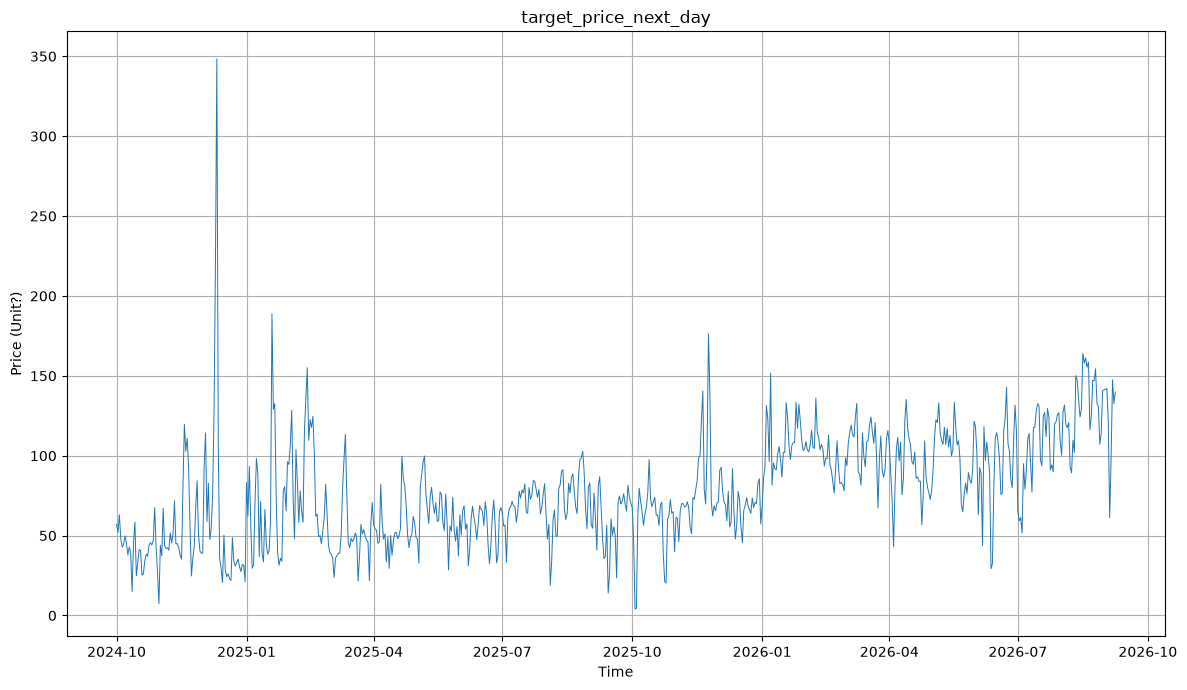

In [41]:
plt.figure(figsize=(12, 7))
plt.plot(data["delivery_day"], data["target_price_next_day"], linewidth=0.7)
plt.xlabel("Time")
plt.ylabel("Price (Unit?)")
plt.title("target_price_next_day")
plt.grid(True)
plt.tight_layout()
plt.show()

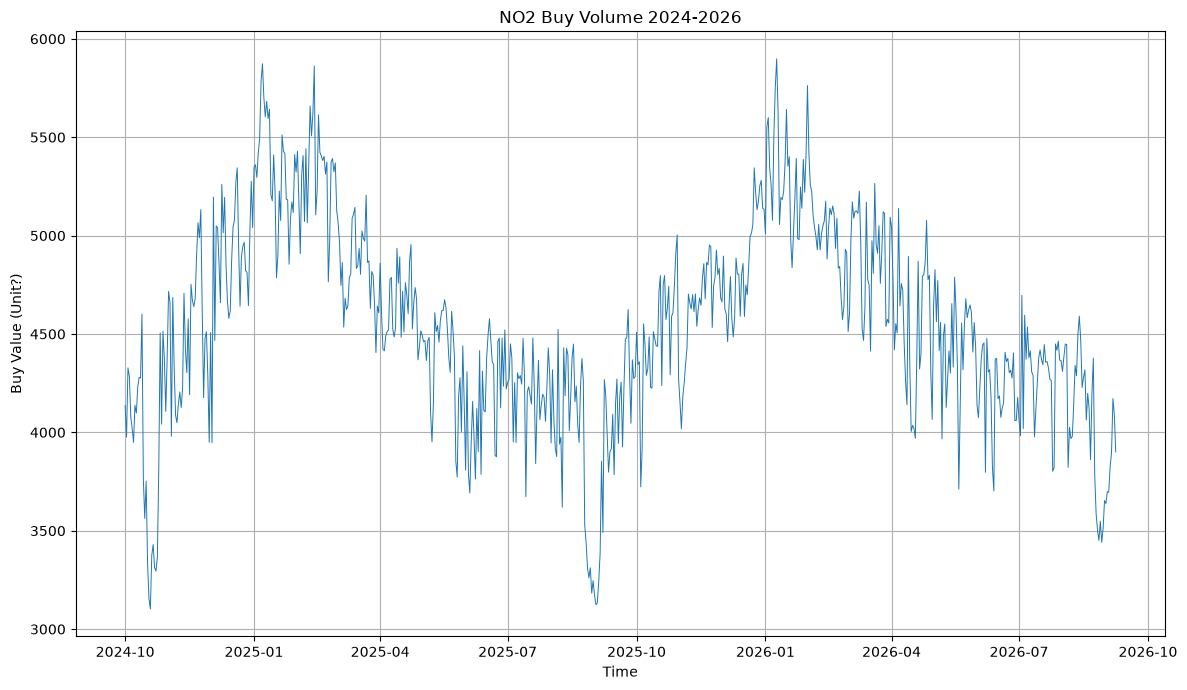

In [42]:
plt.figure(figsize=(12, 7))
plt.plot(data["delivery_day"], data["buy_volume_value"], linewidth=0.7)
plt.xlabel("Time")
plt.ylabel("Buy Value (Unit?)")
plt.title("NO2 Buy Volume 2024-2026")
plt.grid(True)
plt.tight_layout()
plt.show()

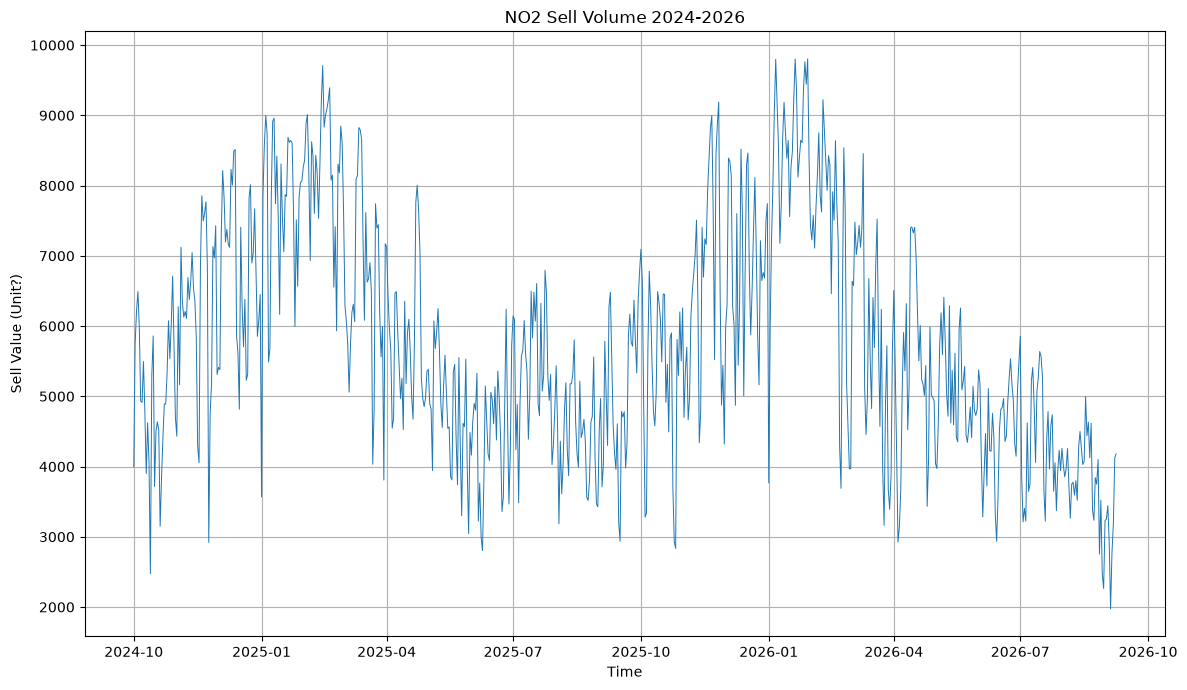

In [43]:
plt.figure(figsize=(12, 7))
plt.plot(data["delivery_day"], data["sell_volume_value"], linewidth=0.7)
plt.xlabel("Time")
plt.ylabel("Sell Value (Unit?)")
plt.title("NO2 Sell Volume 2024-2026")
plt.grid(True)
plt.tight_layout()
plt.show()

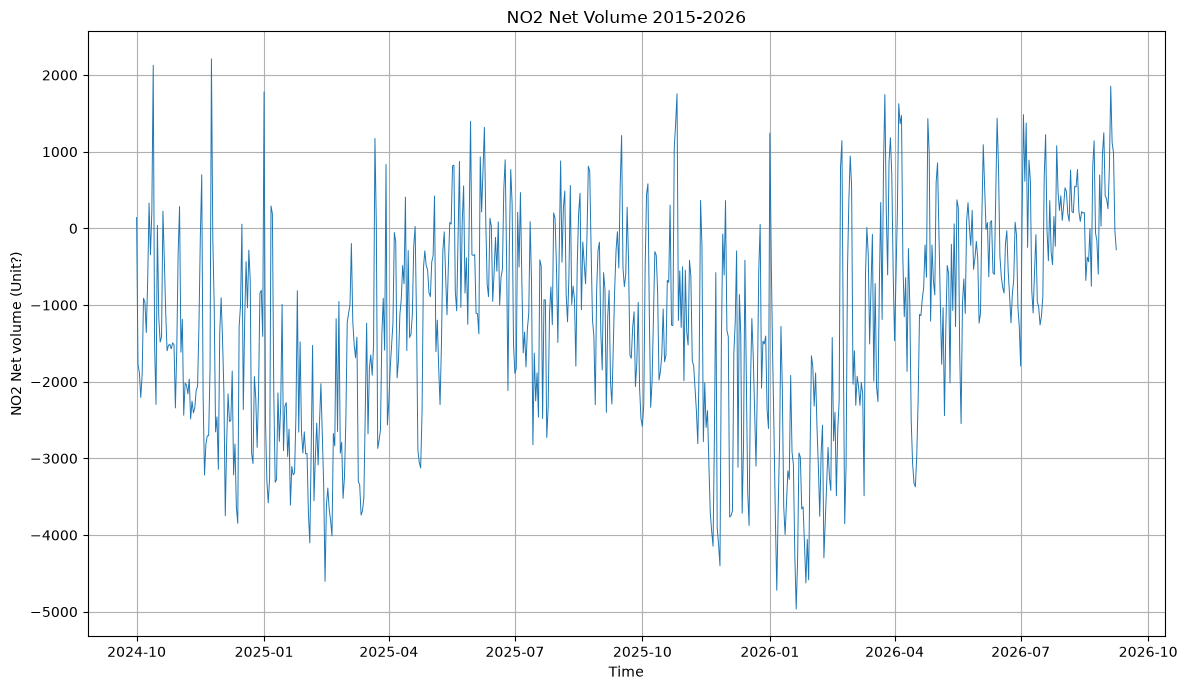

In [44]:
plt.figure(figsize=(12, 7))
plt.plot(data["delivery_day"], data["net_volume"], linewidth=0.7)
plt.xlabel("Time")
plt.ylabel("NO2 Net volume (Unit?)")
plt.title("NO2 Net Volume 2015-2026")
plt.grid(True)
plt.tight_layout()
plt.show()

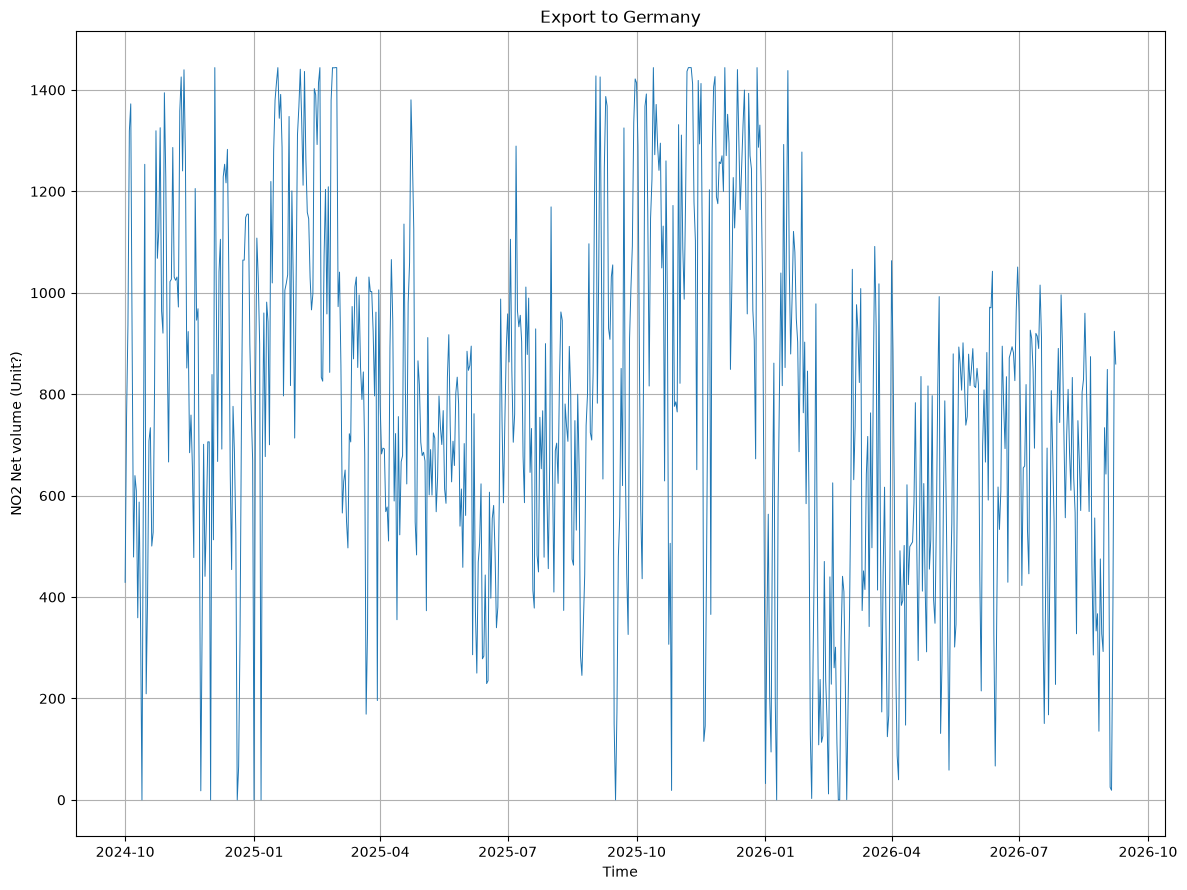

In [45]:
plt.figure(figsize=(12, 9))
plt.plot(
    data["delivery_day"], data['flow_GER_export'], 
    linewidth=0.7)
plt.xlabel("Time")
plt.ylabel("NO2 Net volume (Unit?)")
plt.title("Export to Germany")
plt.grid(True)
plt.tight_layout()
plt.show()

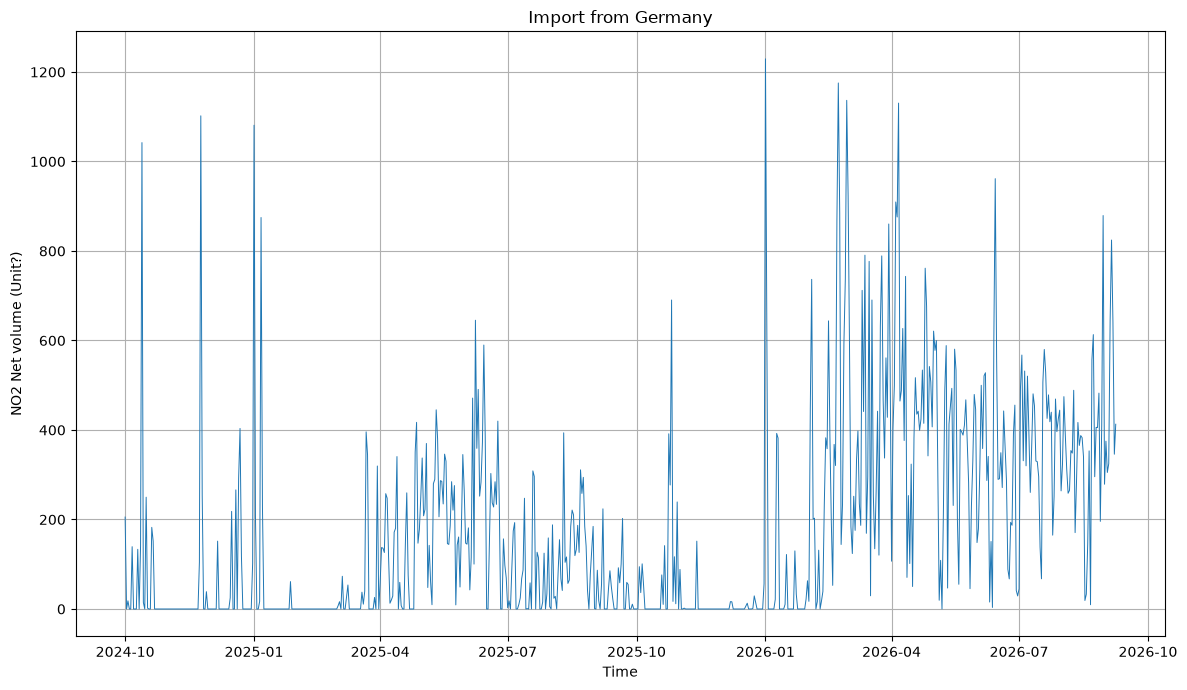

In [46]:
plt.figure(figsize=(12, 7))
plt.plot(
    data["delivery_day"], data['flow_GER_import'],
    linewidth=0.7)
plt.xlabel("Time")
plt.ylabel("NO2 Net volume (Unit?)")
plt.title("Import from Germany")
plt.grid(True)
plt.tight_layout()
plt.show()

In [47]:
data.columns

Index(['delivery_day', 'hour', 'price_value', 'buy_volume_value',
       'sell_volume_value', 'net_volume', 'flow_DK1_export', 'flow_DK1_import',
       'flow_GER_export', 'flow_GER_import',
       ...
       'price_FR_lag168', 'no_2_forecasted_generation_lag168',
       'no_1_forecasted_generation_lag168',
       'no_5_forecasted_generation_lag168',
       'de_lu_forecasted_generation_lag168', 'no_2_forecasted_load_lag168',
       'no_1_forecasted_load_lag168', 'no_5_forecasted_load_lag168',
       'de_lu_forecasted_load_lag168', 'target_price_next_day'],
      dtype='str', length=127)

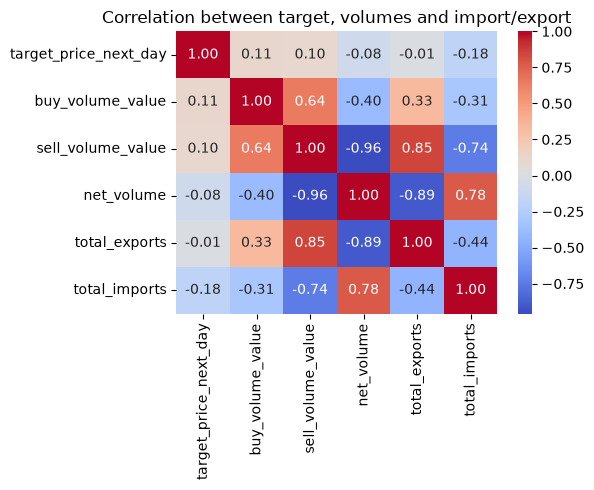

In [48]:
num_cols = [
    'target_price_next_day',
    'buy_volume_value',
    'sell_volume_value',
    'net_volume',
    'total_exports', 
    'total_imports',
]

corr = data[num_cols].corr()

plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation between target, volumes and import/export")
plt.tight_layout()
plt.show()

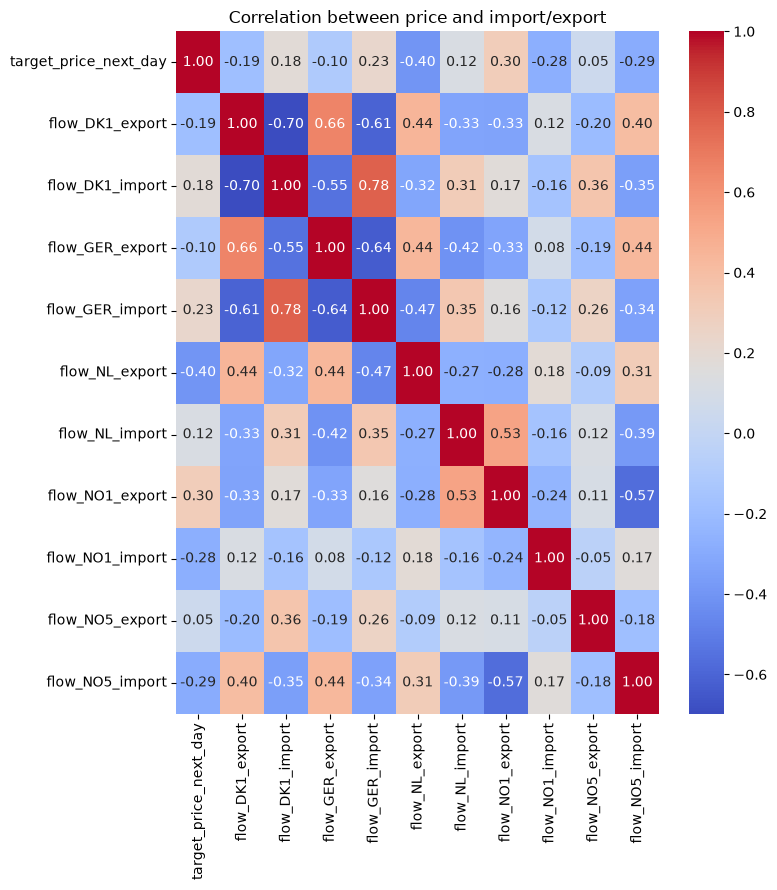

In [49]:
num_cols = [
    'target_price_next_day',
    'flow_DK1_export', 
    'flow_DK1_import',
    'flow_GER_export', 
    'flow_GER_import', 
    'flow_NL_export',
    'flow_NL_import', 
    'flow_NO1_export',
    'flow_NO1_import',
    'flow_NO5_export',
    'flow_NO5_import'
]

corr = data[num_cols].corr()

plt.figure(figsize=(8, 9))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation between price and import/export")
plt.tight_layout()
plt.show()

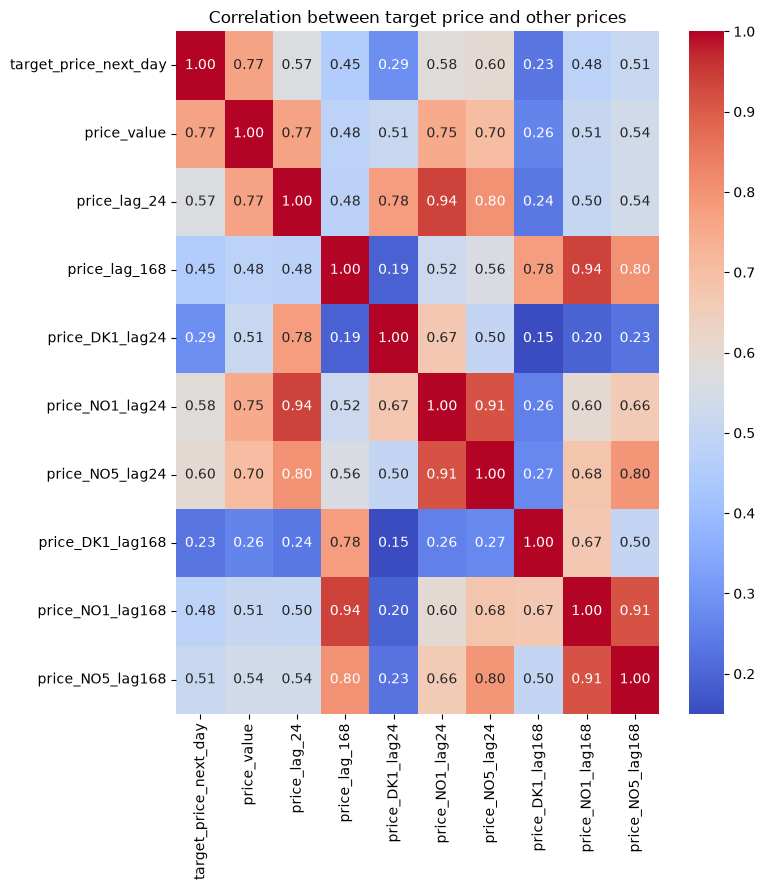

In [50]:
num_cols = [
    'target_price_next_day',
    'price_value',
    'price_lag_24', 
    'price_lag_168', 
    'price_DK1_lag24',
    'price_NO1_lag24', 
    'price_NO5_lag24', 
    'price_DK1_lag168',
    'price_NO1_lag168', 
    'price_NO5_lag168'
]

corr = data[num_cols].corr()

plt.figure(figsize=(8, 9))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation between target price and other prices")
plt.tight_layout()
plt.show()

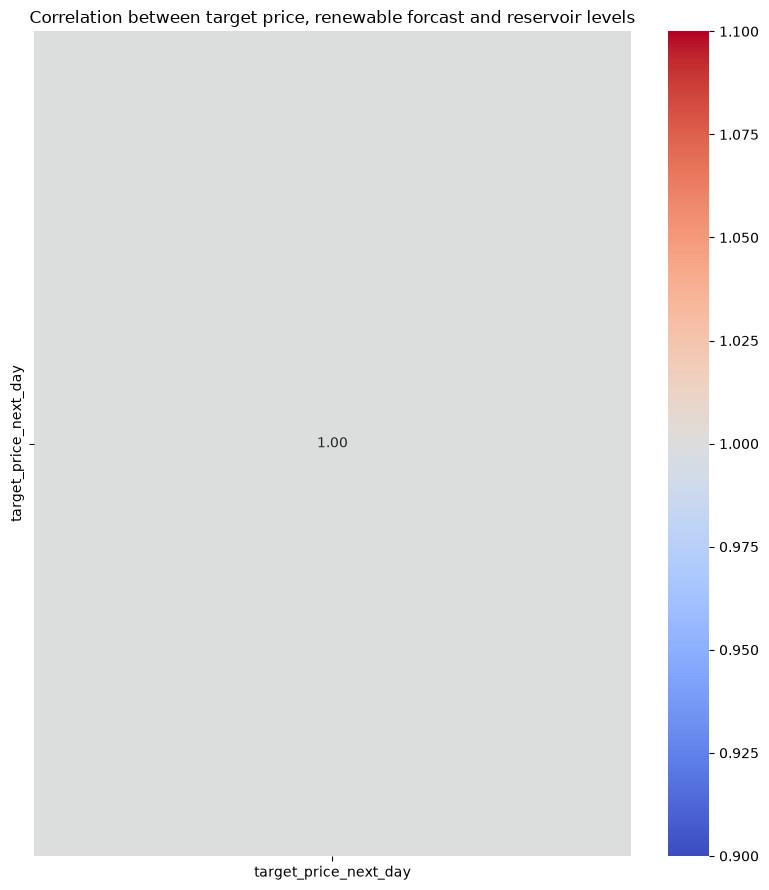

In [51]:
num_cols = [
    'target_price_next_day'
]

corr = data[num_cols].corr()

plt.figure(figsize=(8, 9))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation between target price, renewable forcast and reservoir levels")
plt.tight_layout()
plt.show()

<Figure size 1200x500 with 0 Axes>

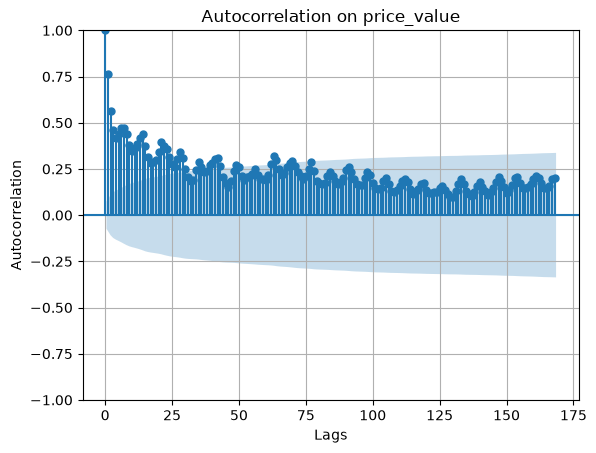

In [52]:
from statsmodels.graphics.tsaplots import plot_acf
plt.figure(figsize=(12,5))
plot_acf(data['target_price_next_day'], lags=168)
plt.xlabel('Lags')
plt.ylabel('Autocorrelation')
plt.title('Autocorrelation on price_value')
plt.grid(True)
plt.show()

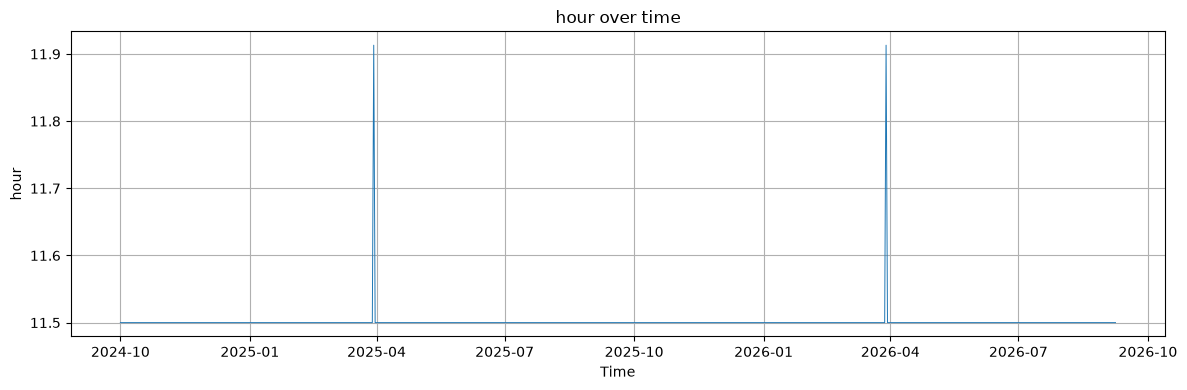

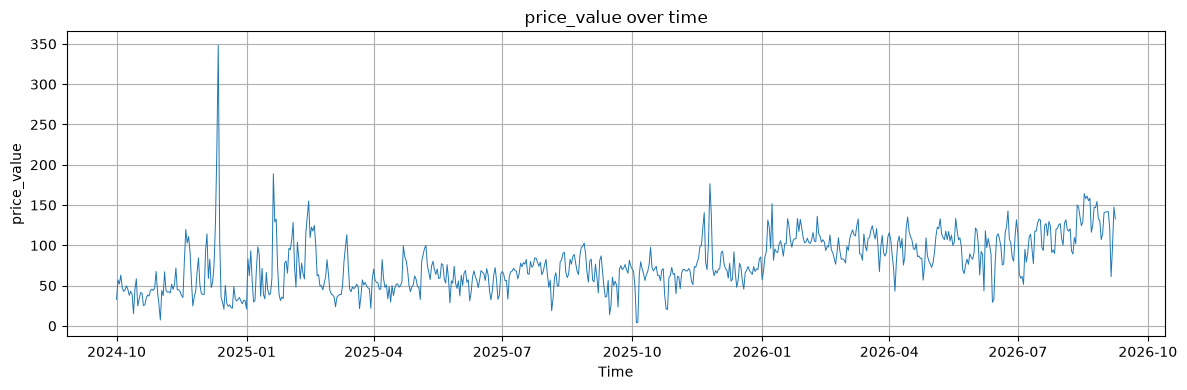

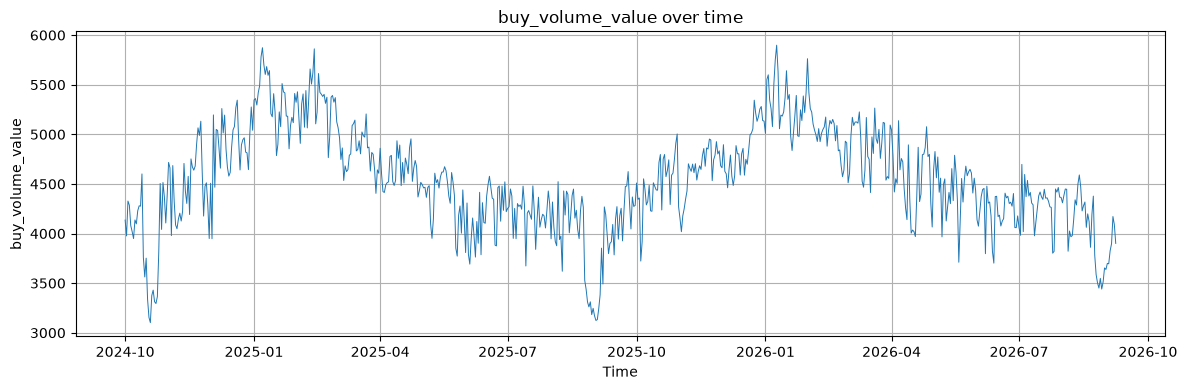

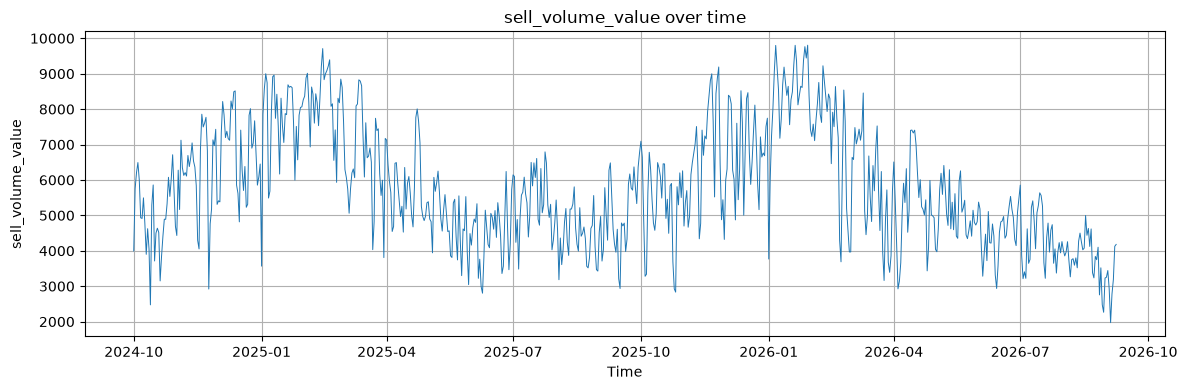

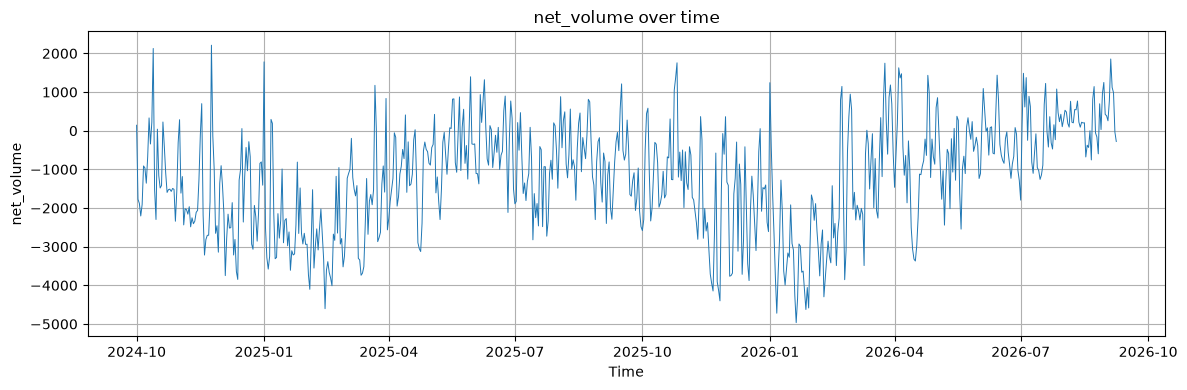

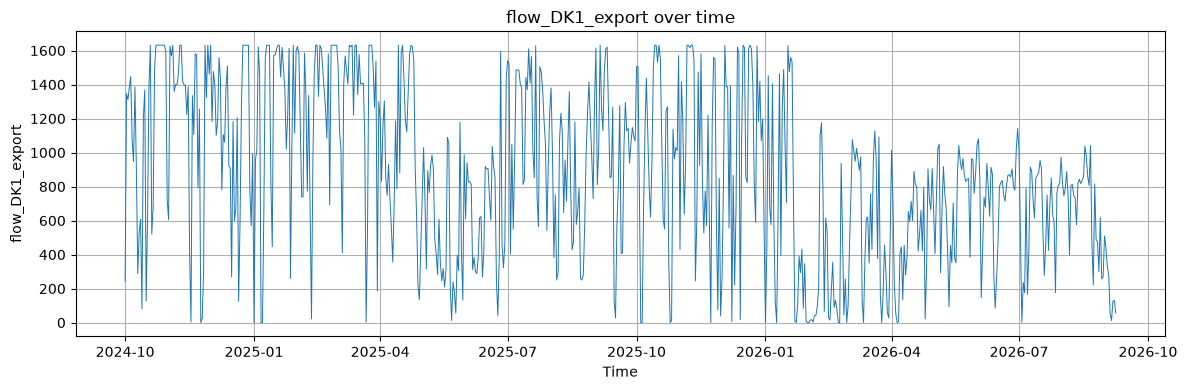

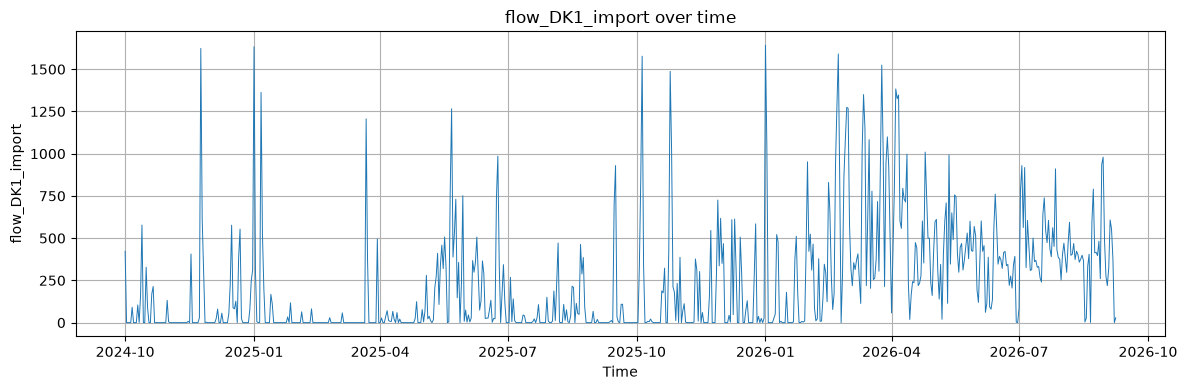

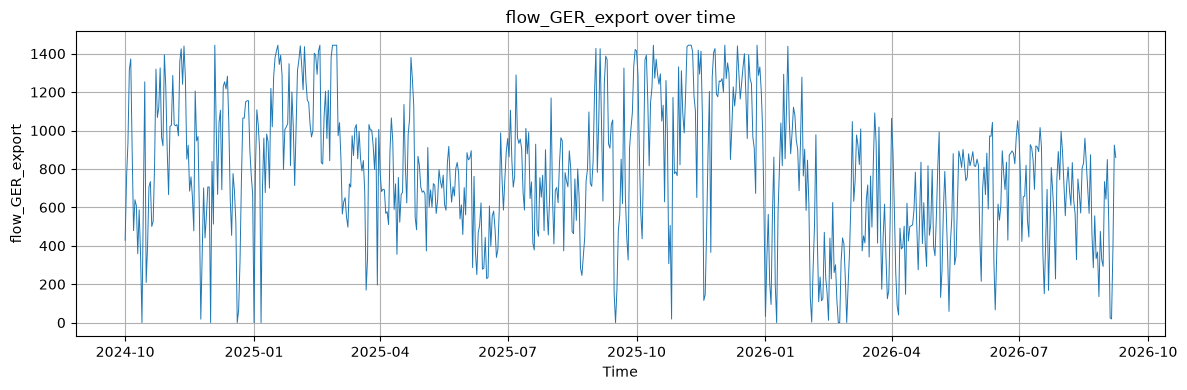

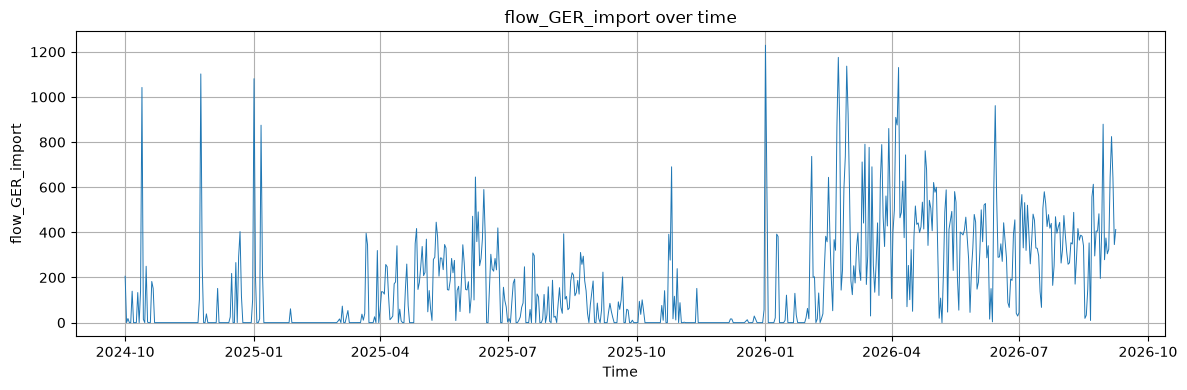

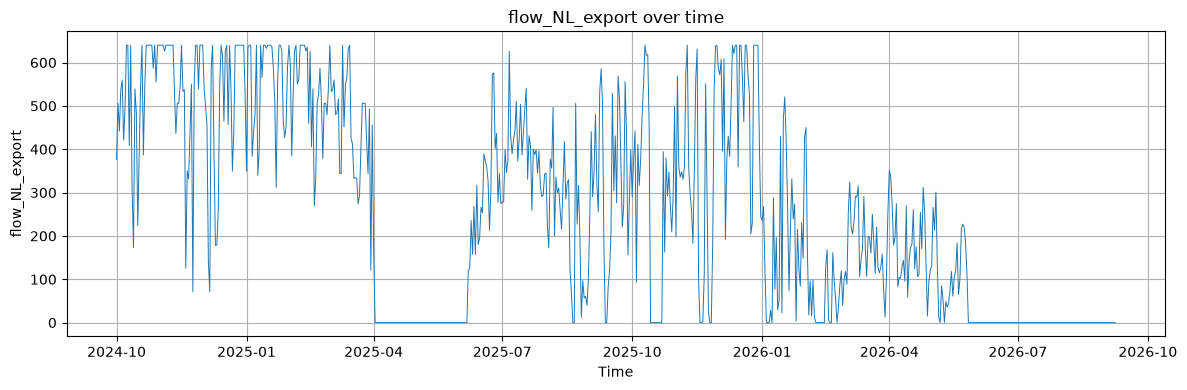

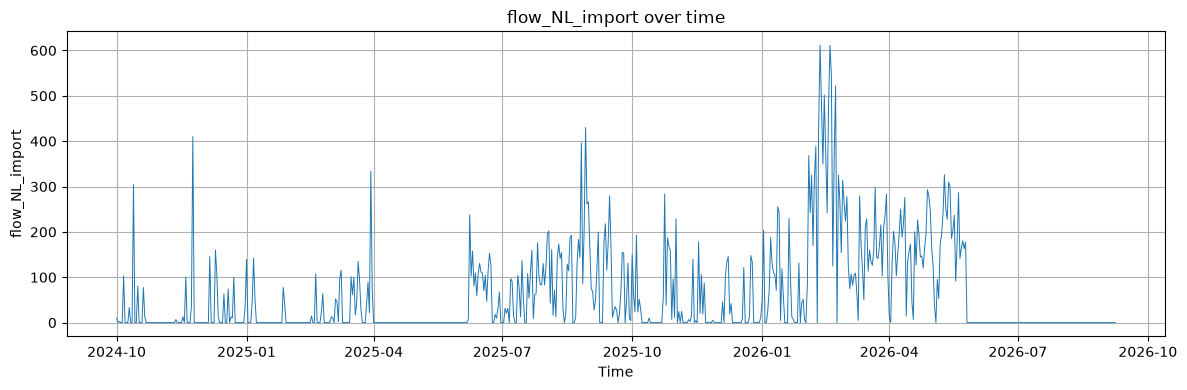

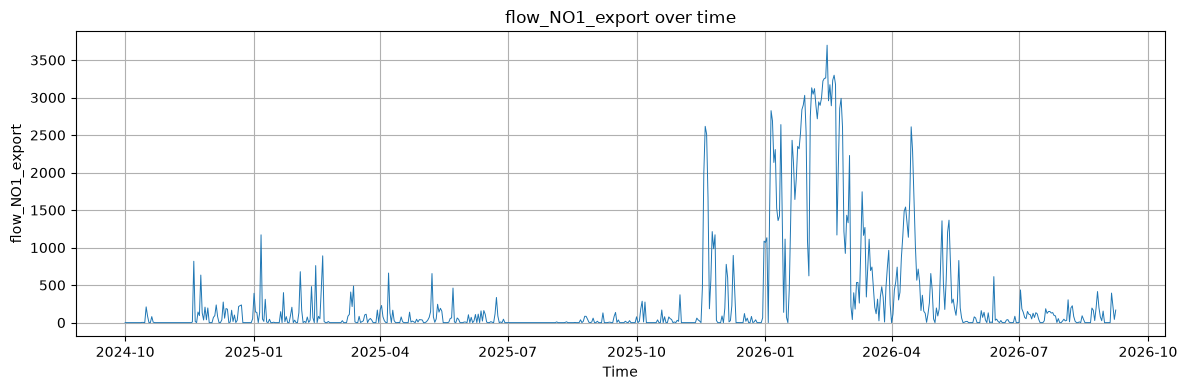

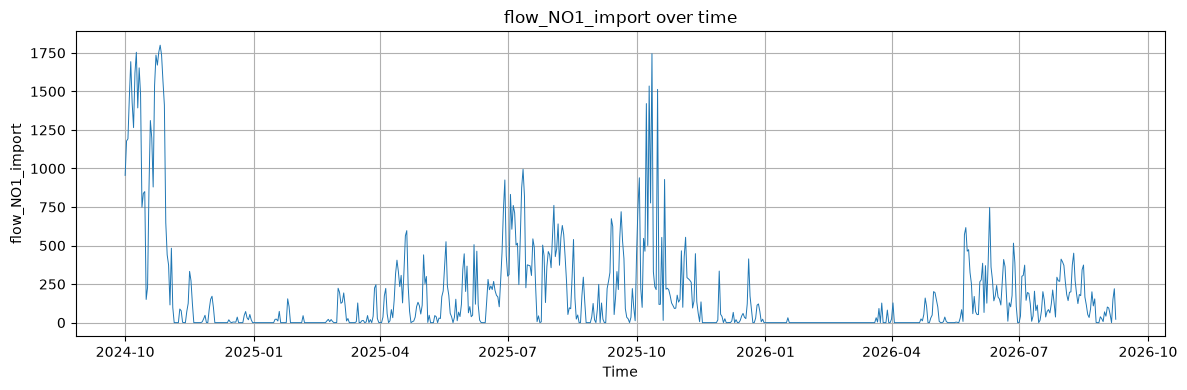

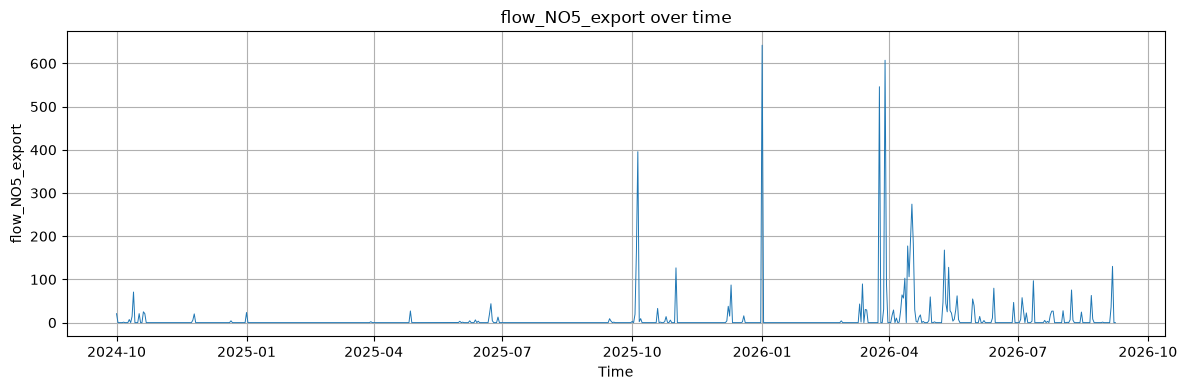

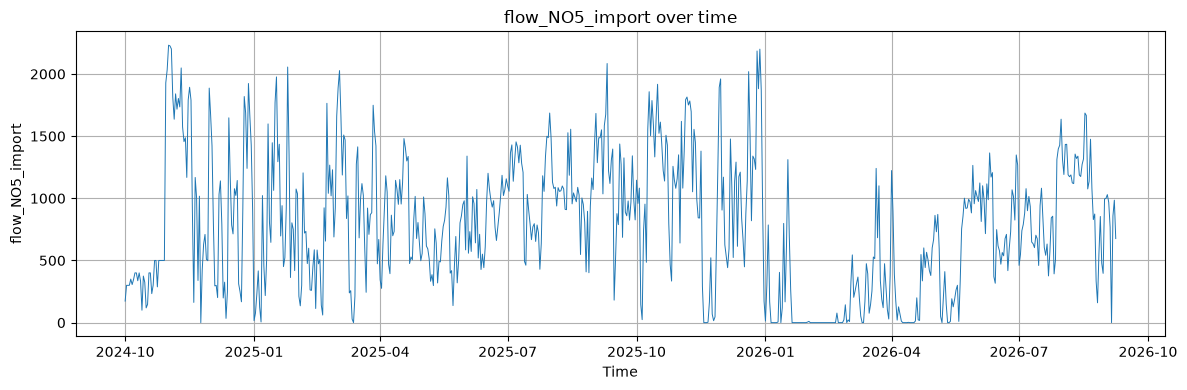

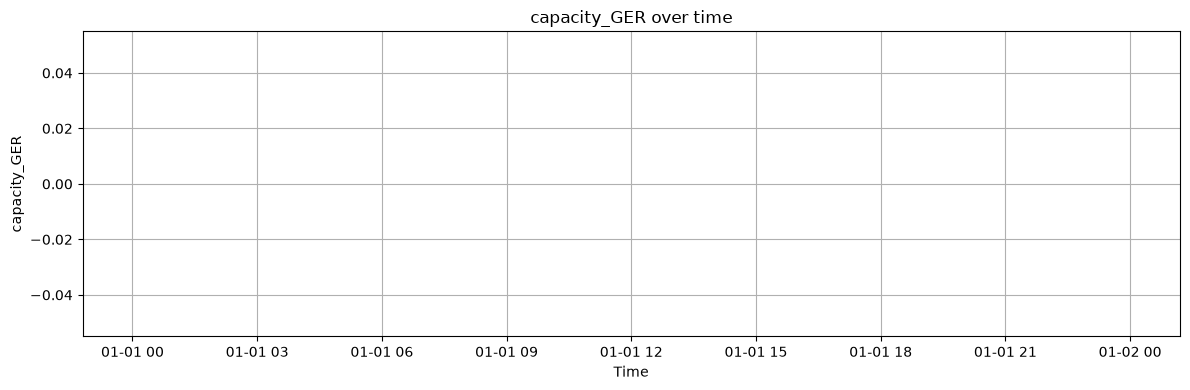

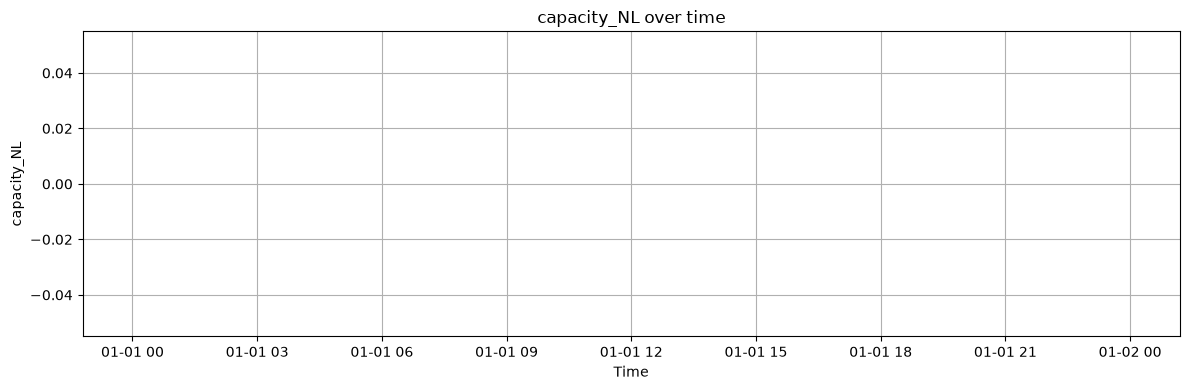

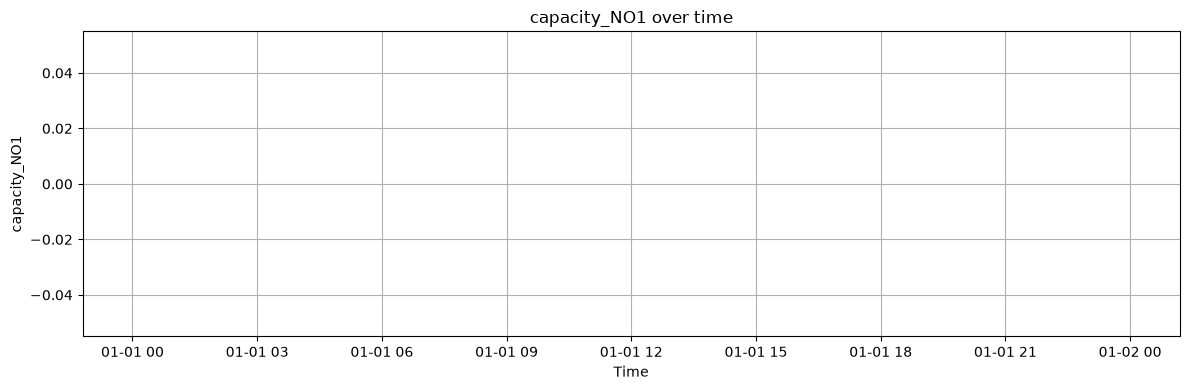

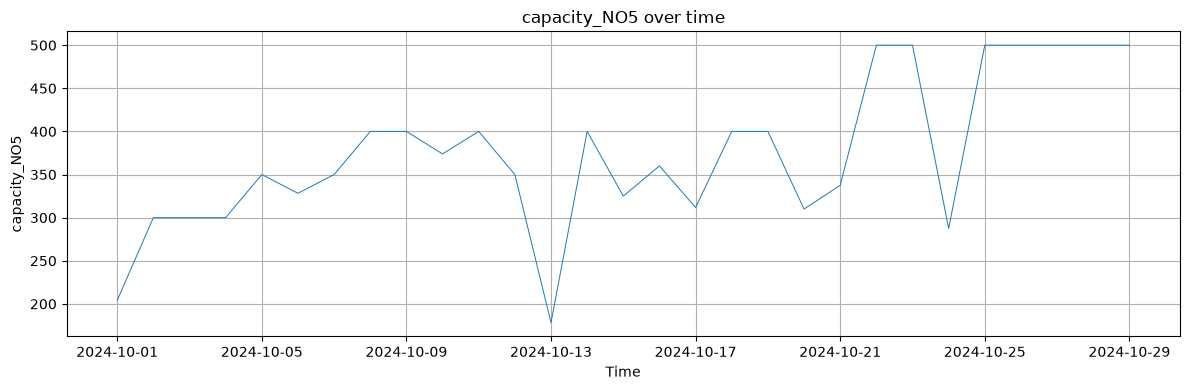

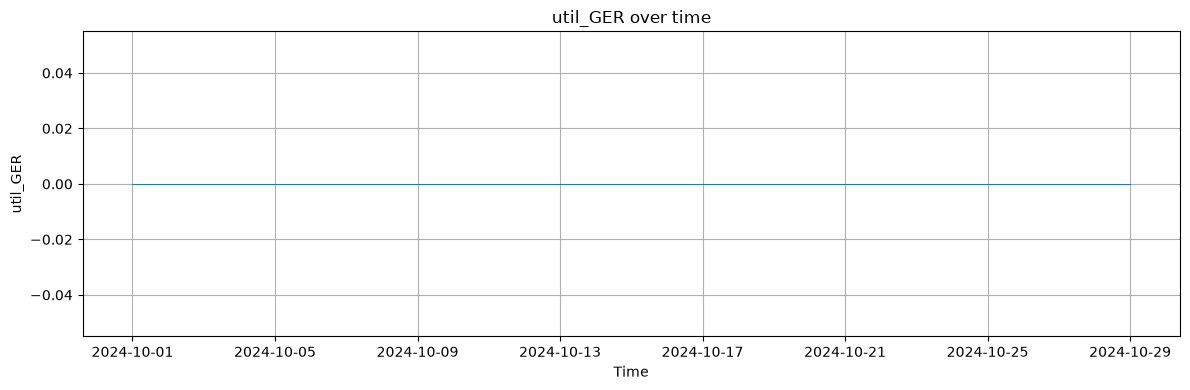

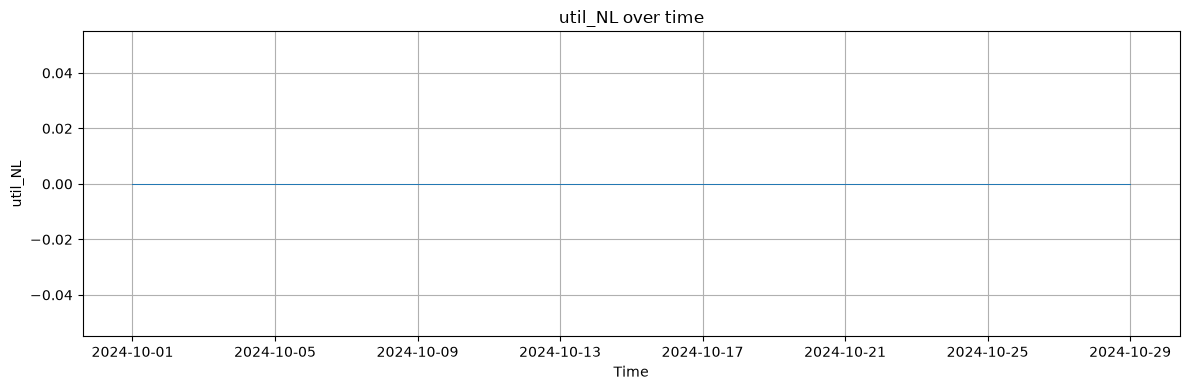

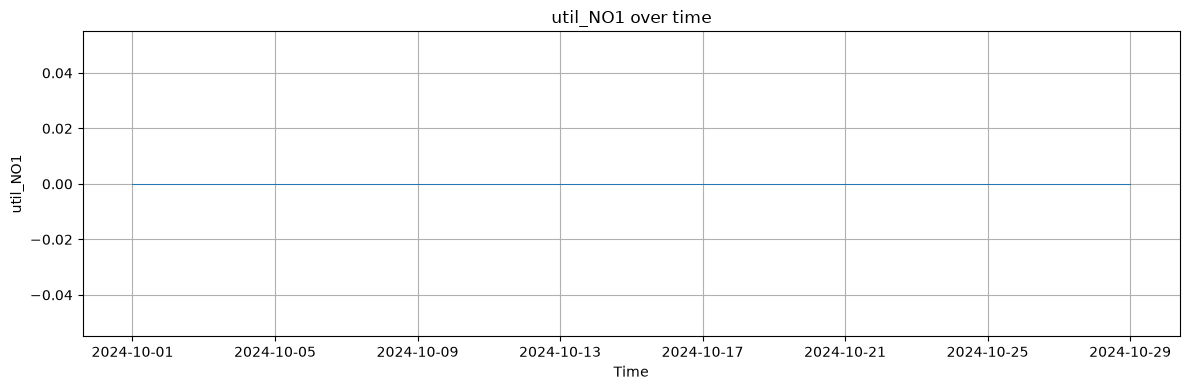

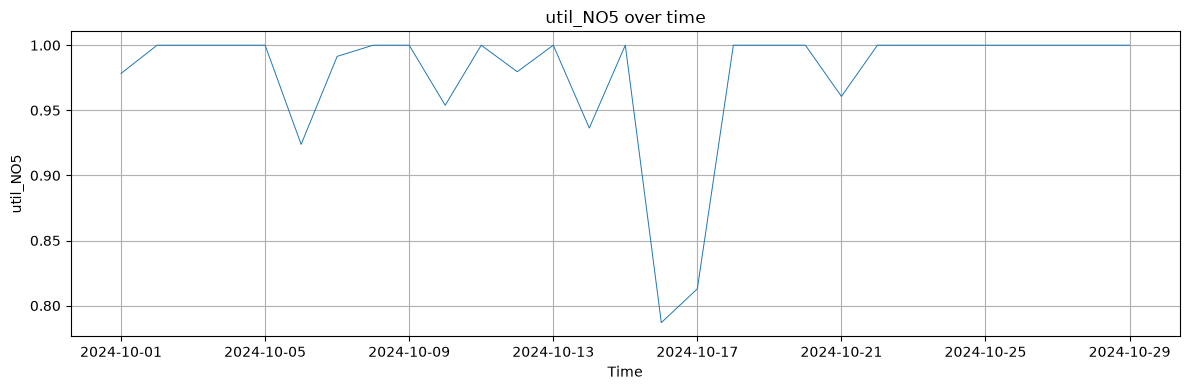

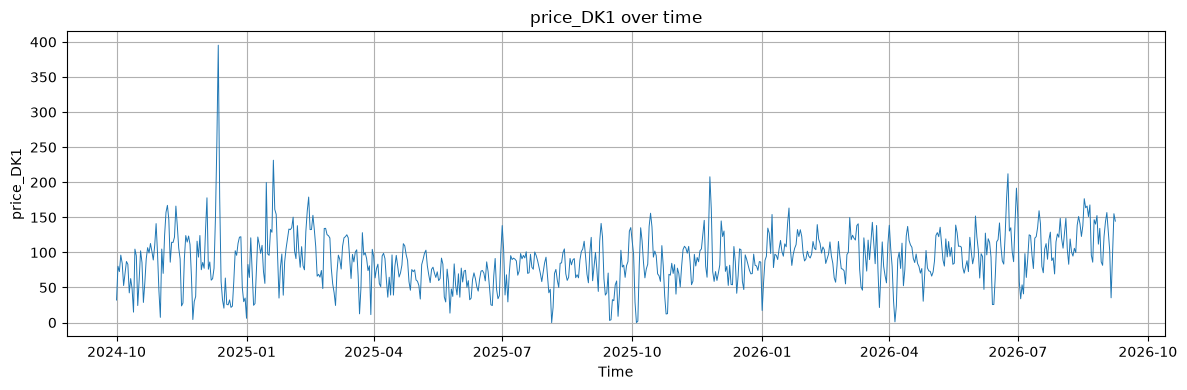

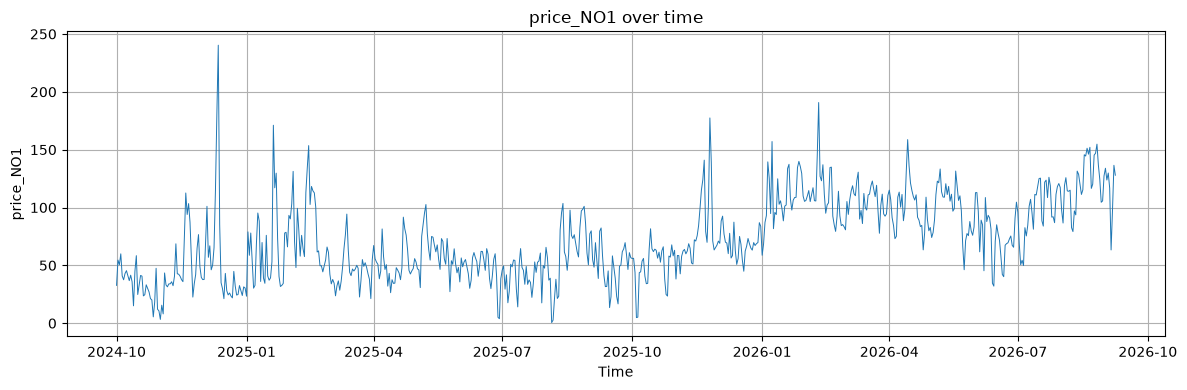

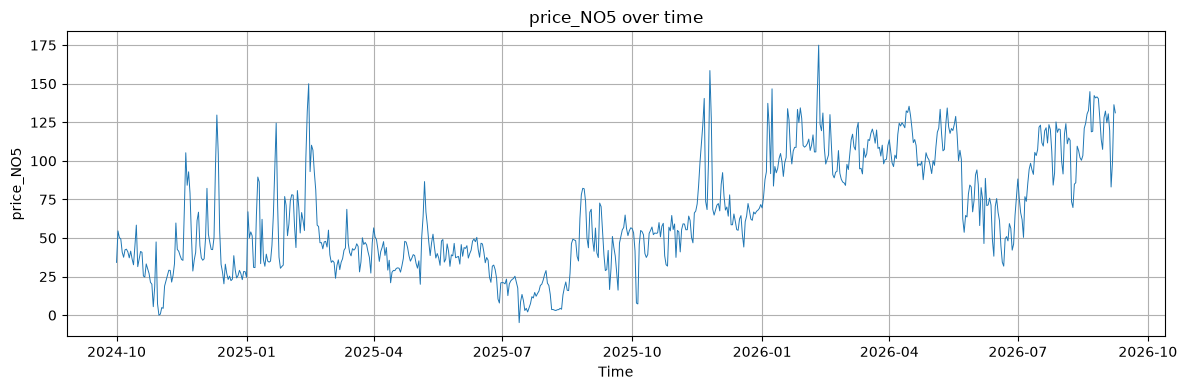

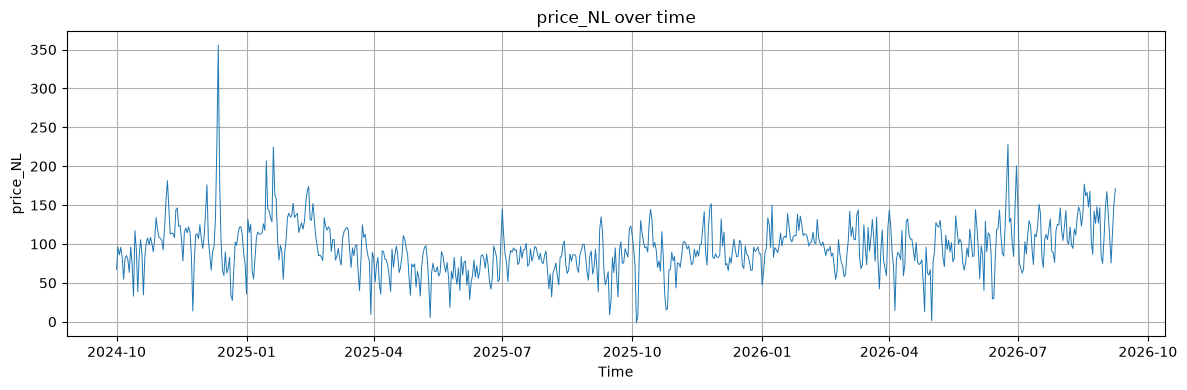

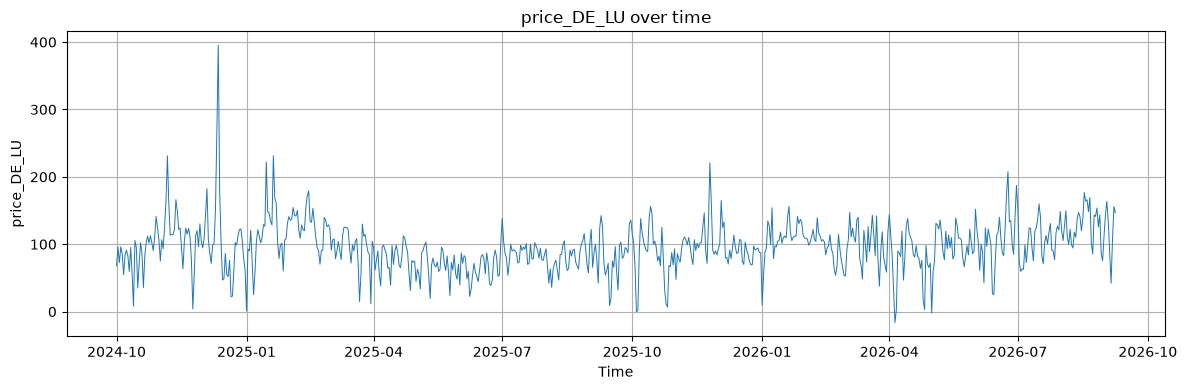

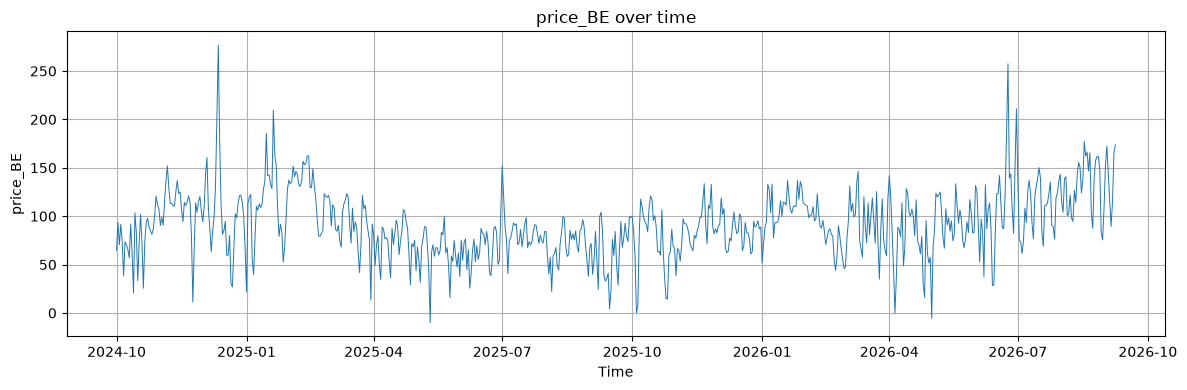

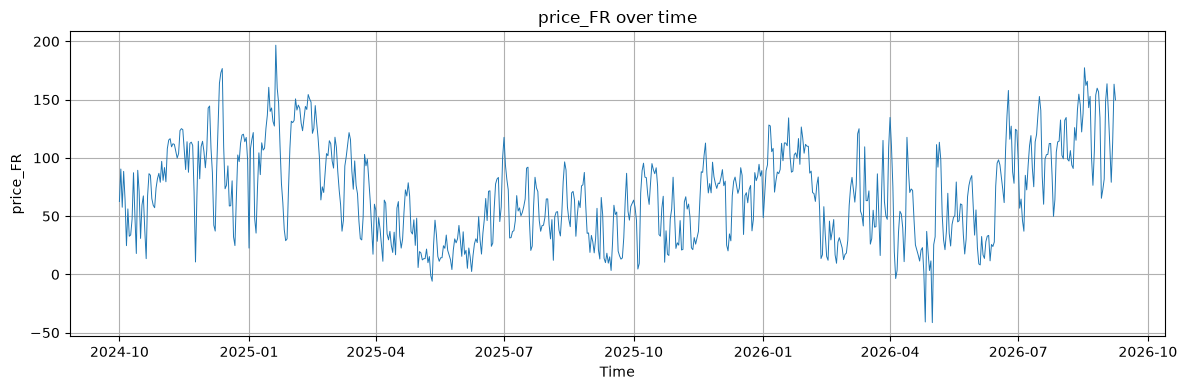

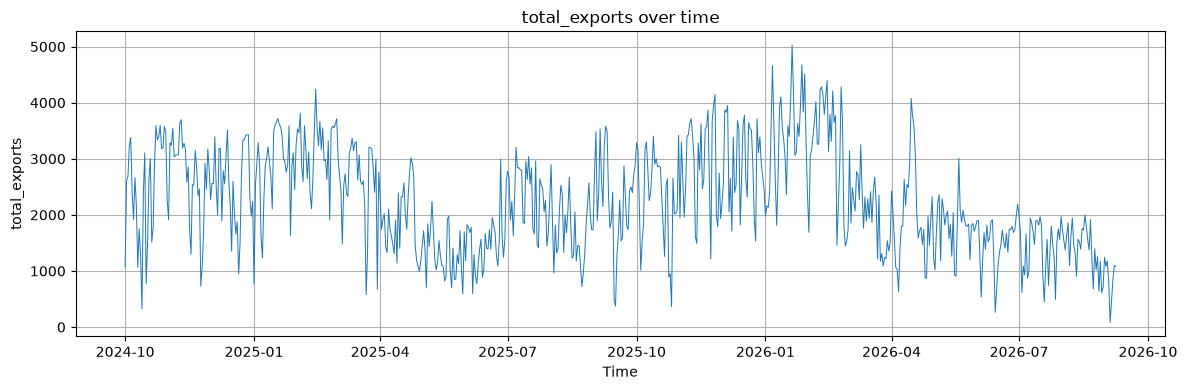

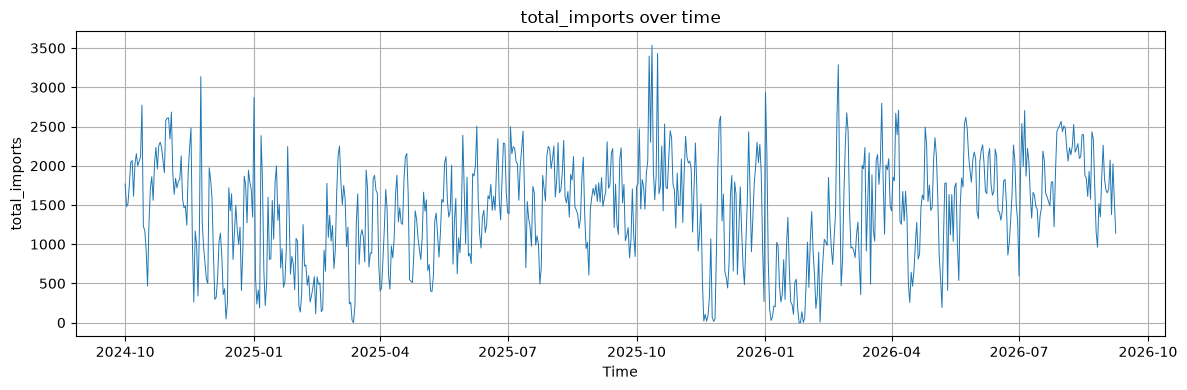

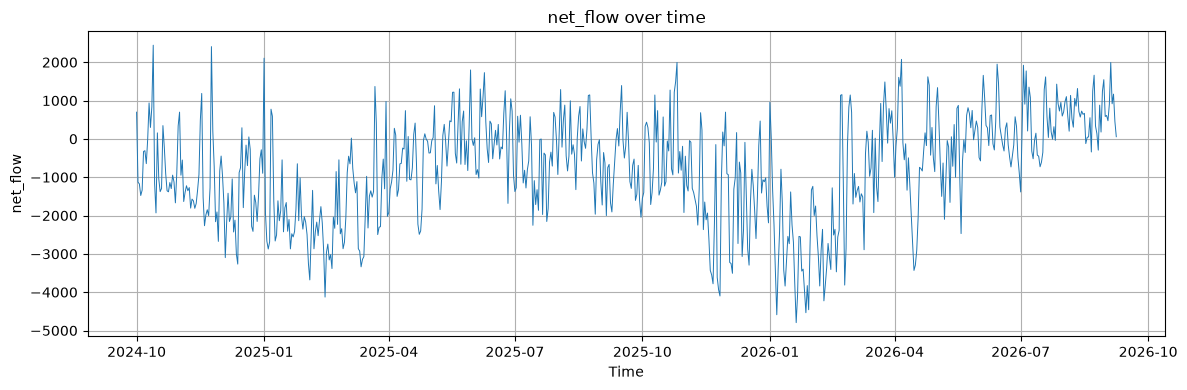

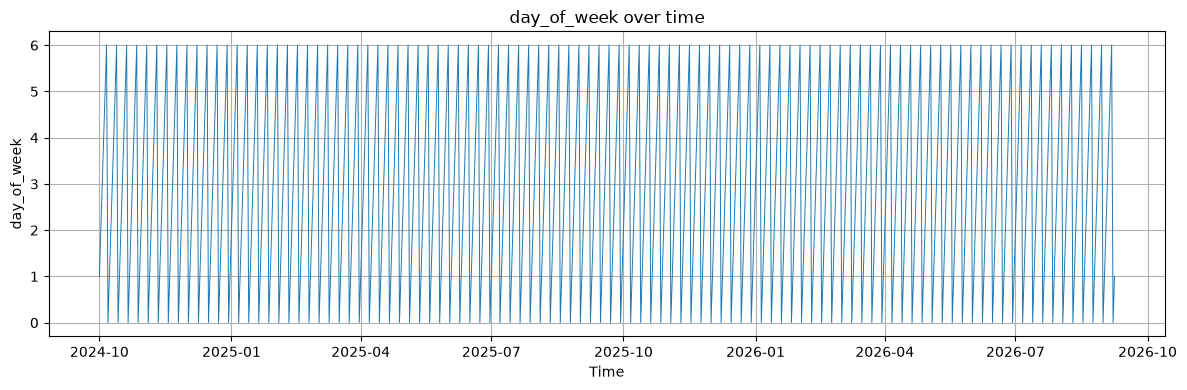

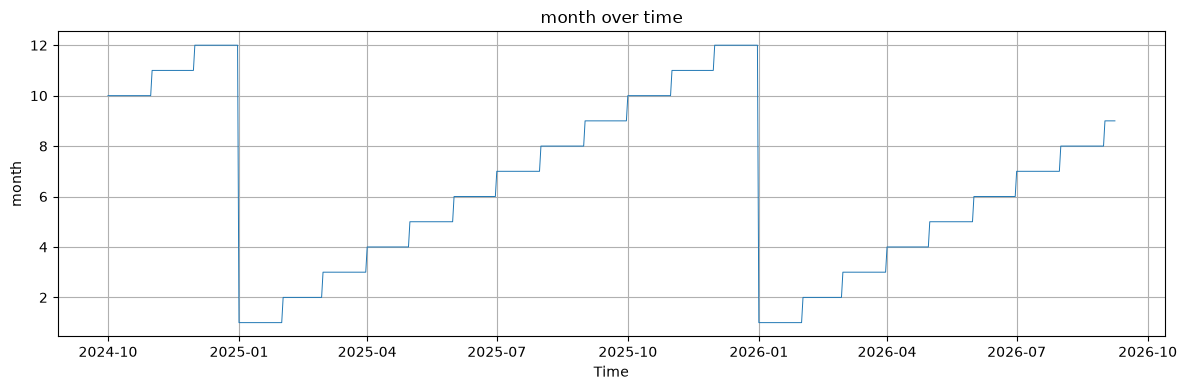

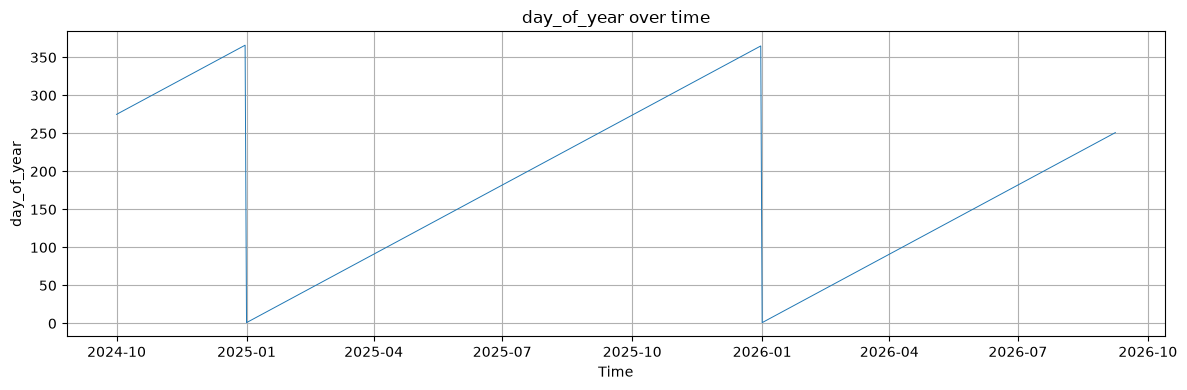

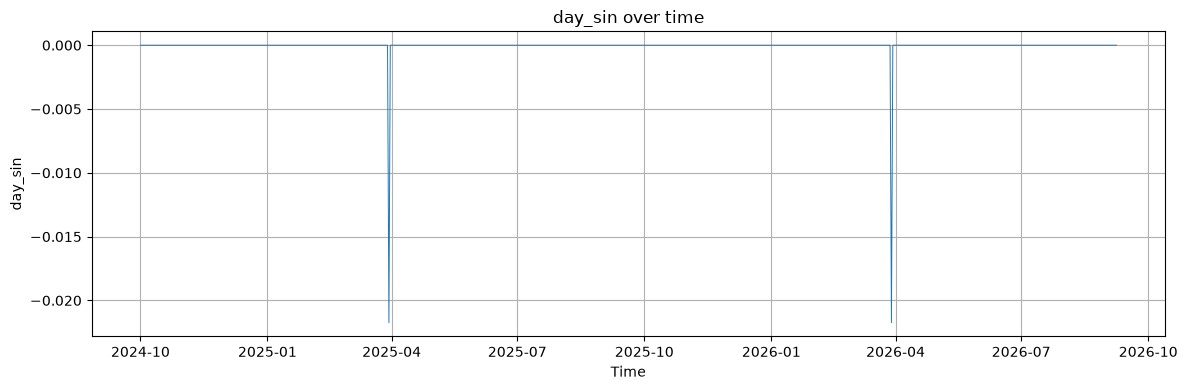

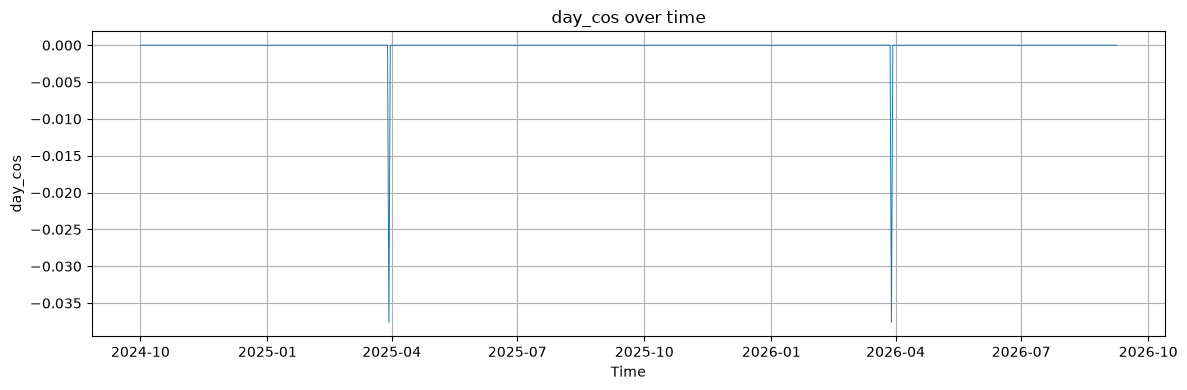

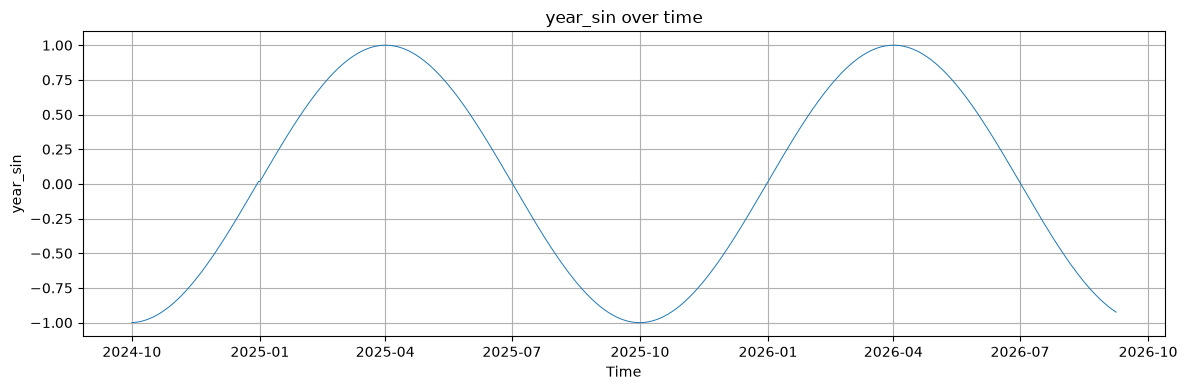

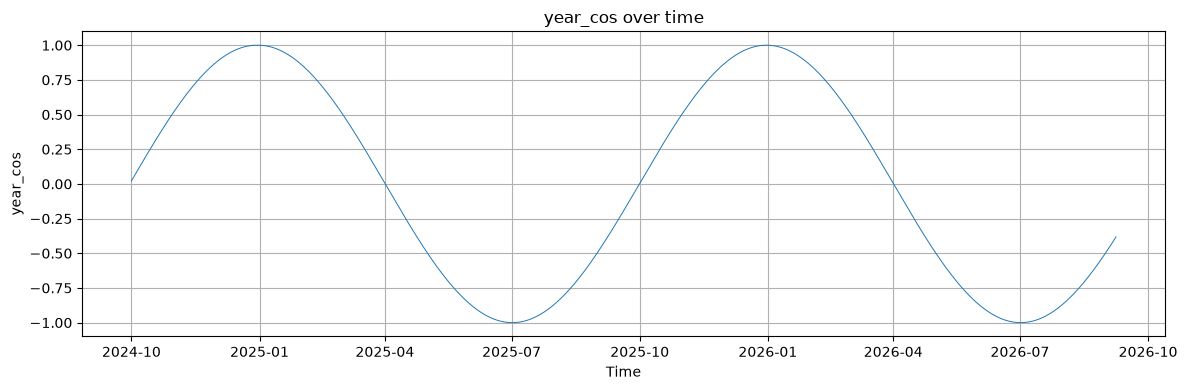

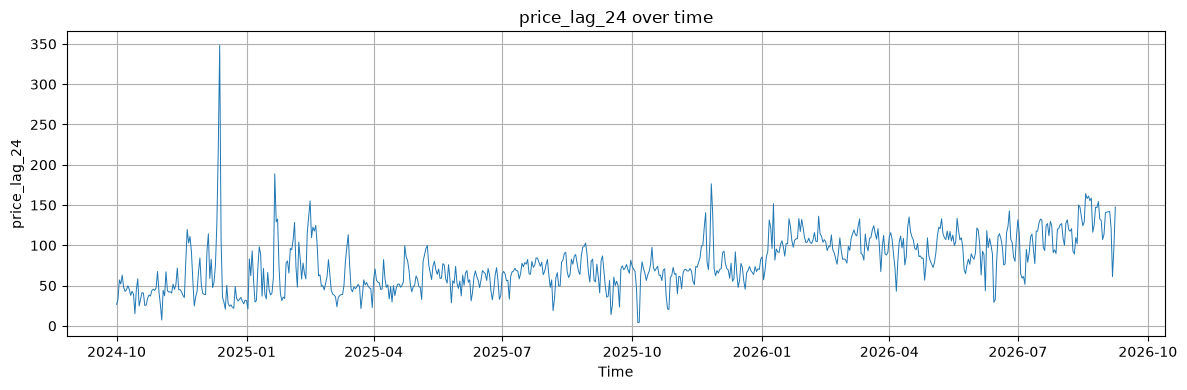

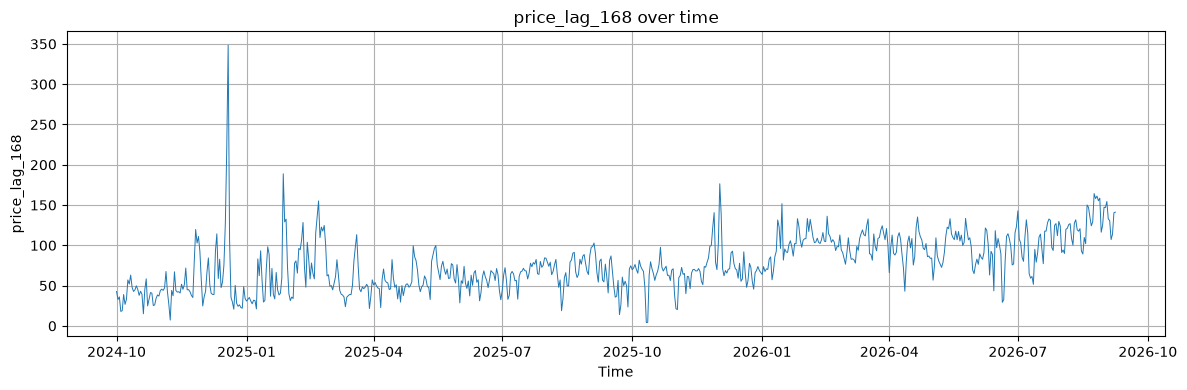

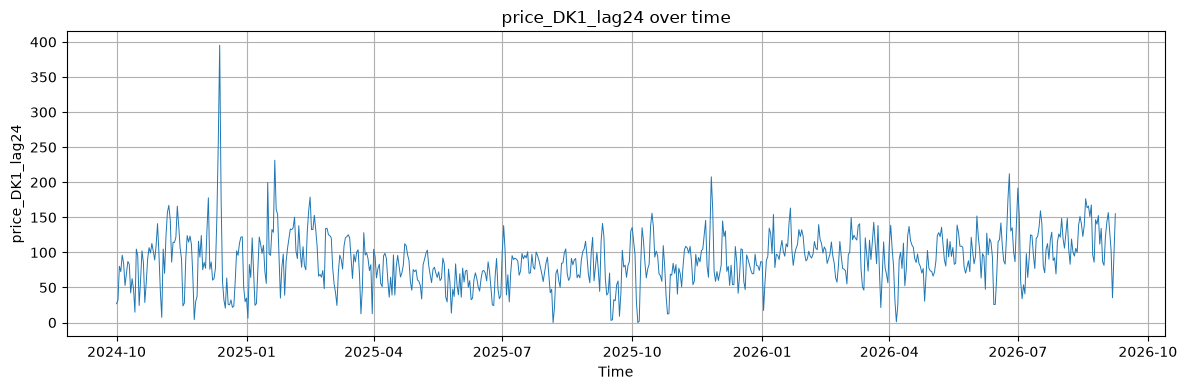

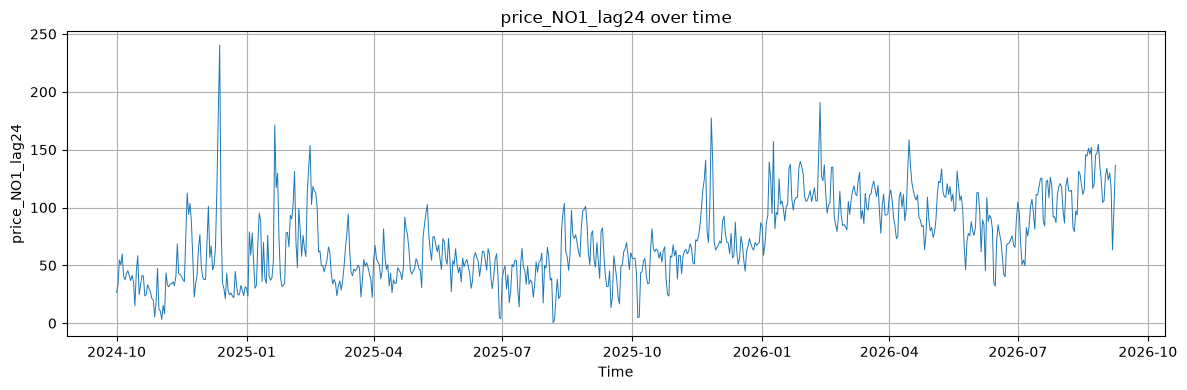

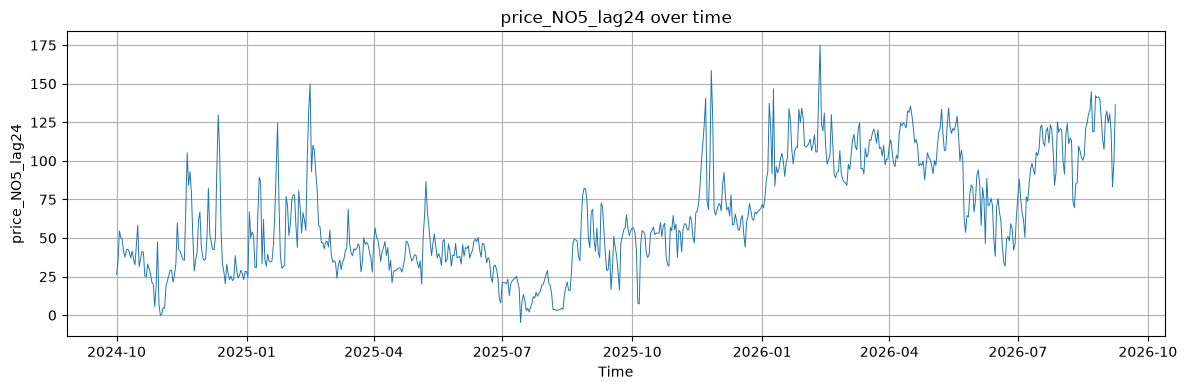

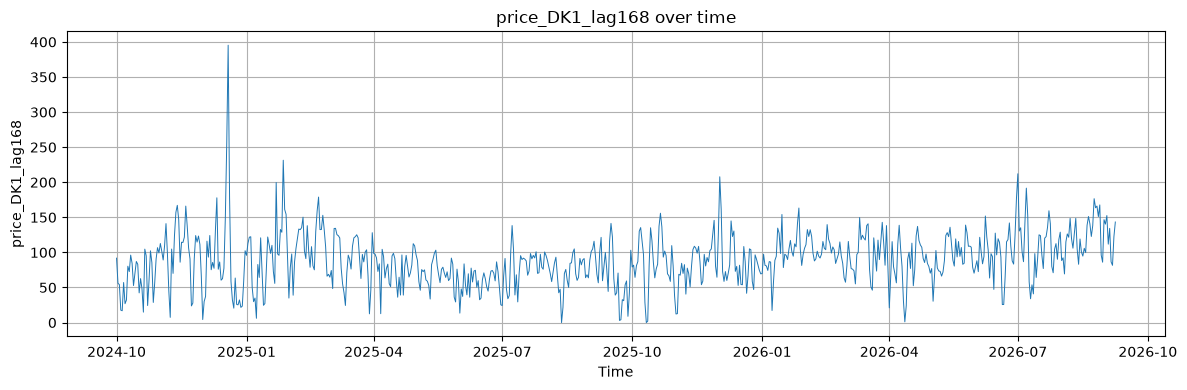

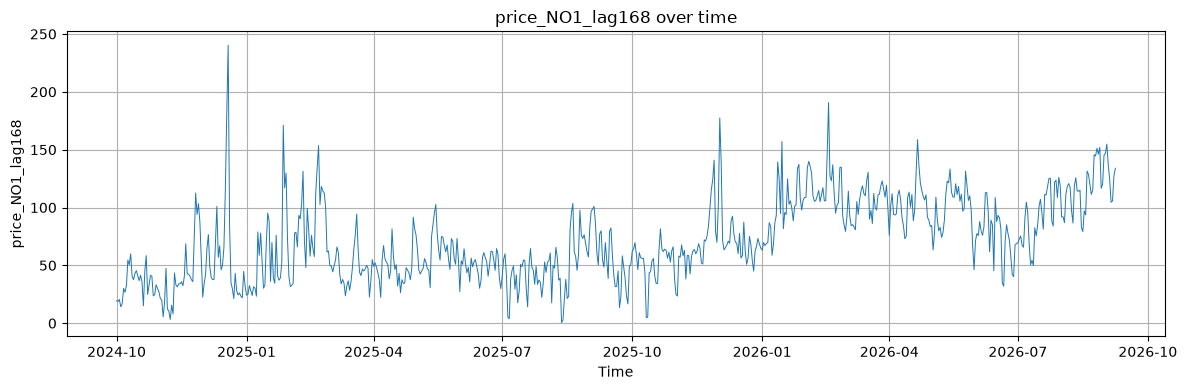

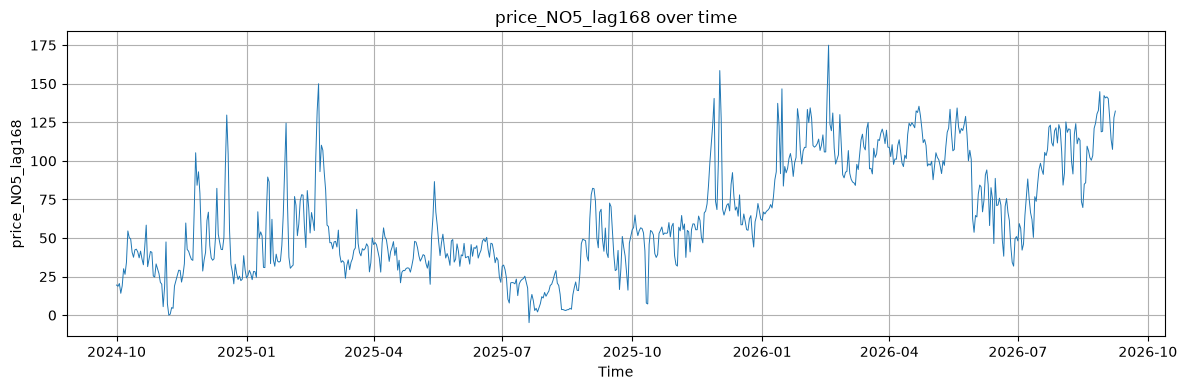

In [53]:
for feature in feature_columns:
    plt.figure(figsize=(12, 4))
    plt.plot(
        data["delivery_day"],
        data[feature],
        linewidth=0.7
    )
    plt.xlabel("Time")
    plt.ylabel(feature)
    plt.title(f"{feature} over time")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

# Common functions

In [54]:
def evaluate(y_true, y_pred):
    return {
        "MSE": mean_squared_error(y_true, y_pred),
        "RMSE": root_mean_squared_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
    }

In [55]:
def plot_results(x_data, test_pred, test_targets, test_pred_label, test_target_label, title, y_label):  
    plt.figure(figsize=(12, 7))
    plt.plot(x_data, test_pred, label=test_pred_label, linewidth=0.7)
    plt.plot(x_data, test_targets, label=test_target_label, linewidth=0.7)
    plt.xlabel("Time")
    plt.ylabel(y_label)
    plt.title(title)
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()

# Testing Models

In [56]:
feature_data = data[feature_columns]
target_data = data['target_price_next_day']

## Random forest regressor

Random forest regressor scores:
  MSE: 188.1870
  RMSE: 13.7181
  R2: 0.3683


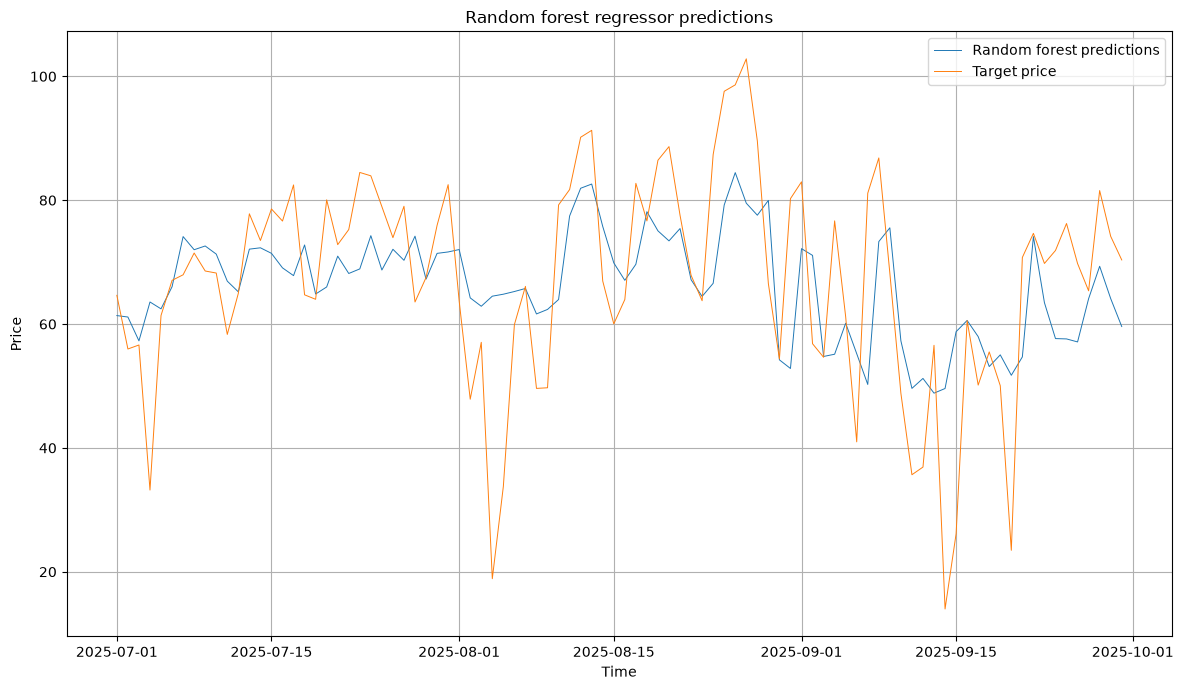

In [67]:
# Use the seasonal split defined in the Load dataset cell
test_period, test_mask, train_mask = seasonal_splits[0]

# April-June 2025 is used for training and validation
train_data_all = feature_data.loc[train_mask]
train_targets_all = target_data.loc[train_mask]

# July-September 2025 is kept completely separate as the final test set
test_data = feature_data.loc[test_mask]
test_targets = target_data.loc[test_mask]

# Split the training season chronologically:
# first 85% for training, last 15% for validation
validation_end = int(len(train_data_all) * 0.85)

train_data = train_data_all.iloc[:validation_end]
train_targets = train_targets_all.iloc[:validation_end]

validation_data = train_data_all.iloc[validation_end:]
validation_targets = train_targets_all.iloc[validation_end:]


rf_model = RandomForestRegressor(
        n_estimators=300,
        random_state=42,
        n_jobs=-1,
    )

rf_model.fit(train_data, train_targets)

rf_test_pred = rf_model.predict(test_data)


rf_test_scores = evaluate(test_targets, rf_test_pred)

print("Random forest regressor scores:")
for name, score in rf_test_scores.items():
    print(f"  {name}: {score:.4f}")

x_data = data.loc[test_data.index, "delivery_day"]
plot_results(x_data=x_data, 
             test_pred=rf_test_pred, 
             test_targets=test_targets, 
             test_pred_label="Random forest predictions", 
             test_target_label="Target price", 
             title="Random forest regressor predictions", 
             y_label="Price")


## Dummy regressor

Dummy regressor scores:
  MSE: 2008.0232
  RMSE: 44.8110
  R2: -1.8422


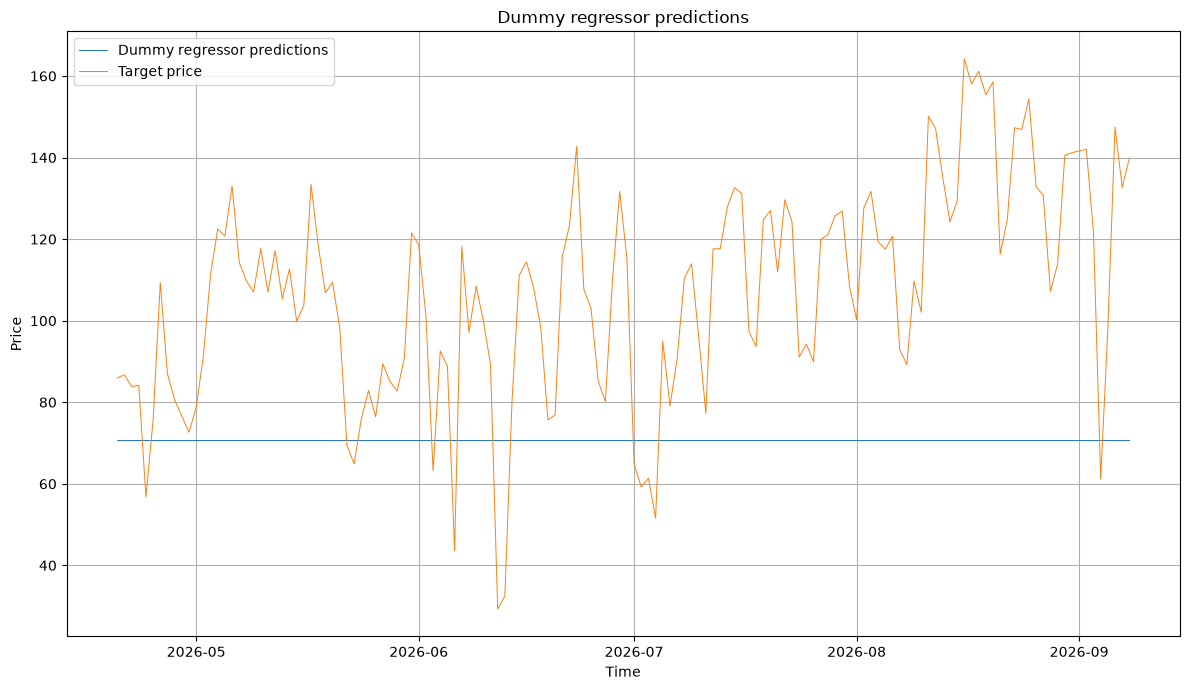

In [58]:
dummy_model = DummyRegressor(strategy="mean")
dummy_model.fit(train_data, train_targets)

dummy_test_pred = dummy_model.predict(test_data)

dummy_test_scores = evaluate(test_targets, dummy_test_pred)

print("Dummy regressor scores:")
for name, score in dummy_test_scores.items():
    print(f"  {name}: {score:.4f}")


x_data = data.loc[test_data.index, "delivery_day"]
plot_results(x_data=x_data, 
             test_pred=dummy_test_pred, 
             test_targets=test_targets, 
             test_pred_label="Dummy regressor predictions", 
             test_target_label="Target price", 
             title="Dummy regressor predictions", 
             y_label="Price")


# XGBoost Regressor

In [59]:
# Use the seasonal split defined in the Load dataset cell
test_period, test_mask, train_mask = seasonal_splits[0]

# April-June 2025 is used for training and validation
train_data_all = feature_data.loc[train_mask]
train_targets_all = target_data.loc[train_mask]

# July-September 2025 is kept completely separate as the final test set
test_data = feature_data.loc[test_mask]
test_targets = target_data.loc[test_mask]

# Split the training season chronologically:
# first 85% for training, last 15% for validation
validation_end = int(len(train_data_all) * 0.85)

train_data = train_data_all.iloc[:validation_end]
train_targets = train_targets_all.iloc[:validation_end]

validation_data = train_data_all.iloc[validation_end:]
validation_targets = train_targets_all.iloc[validation_end:]

# print(f"Seasonal test: {test_period}")
# print(f"Training rows: {len(train_data)}")
# print(f"Validation rows: {len(validation_data)}")
# print(f"Test rows: {len(test_data)}")


xgb_model = XGBRegressor(
    n_estimators=300,
    max_depth=2,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.6,
    random_state=42,
    n_jobs=-1,
    verbosity=0
)

xgb_model.fit(
    train_data,
    train_targets,
    eval_set=[(validation_data, validation_targets)],
    verbose=True,
)

xgb_val_pred = xgb_model.predict(validation_data)
xgb_test_pred = xgb_model.predict(test_data)

xgb_val_scores = evaluate(validation_targets, xgb_val_pred)
xgb_test_scores = evaluate(test_targets, xgb_test_pred)

print("XGBoost regressor validation scores:")
for name, score in xgb_val_scores.items():
    print(f"  {name}: {score:.4f}")

print("XGBoost regressor test scores:")
for name, score in xgb_test_scores.items():
    print(f"  {name}: {score:.4f}")


[0]	validation_0-rmse:14.03322
[1]	validation_0-rmse:13.96807
[2]	validation_0-rmse:13.88770
[3]	validation_0-rmse:13.83283
[4]	validation_0-rmse:13.84641
[5]	validation_0-rmse:13.79384
[6]	validation_0-rmse:13.74153
[7]	validation_0-rmse:13.76293
[8]	validation_0-rmse:13.69608
[9]	validation_0-rmse:13.70194
[10]	validation_0-rmse:13.69352
[11]	validation_0-rmse:13.65224
[12]	validation_0-rmse:13.59003
[13]	validation_0-rmse:13.50290
[14]	validation_0-rmse:13.50653
[15]	validation_0-rmse:13.47864
[16]	validation_0-rmse:13.38561
[17]	validation_0-rmse:13.27938
[18]	validation_0-rmse:13.22051
[19]	validation_0-rmse:13.20184
[20]	validation_0-rmse:13.21300
[21]	validation_0-rmse:13.16497
[22]	validation_0-rmse:13.13379
[23]	validation_0-rmse:13.10123
[24]	validation_0-rmse:13.04809
[25]	validation_0-rmse:13.00332
[26]	validation_0-rmse:12.97629
[27]	validation_0-rmse:12.98013
[28]	validation_0-rmse:12.95198
[29]	validation_0-rmse:12.90043
[30]	validation_0-rmse:12.83533
[31]	validation_0-

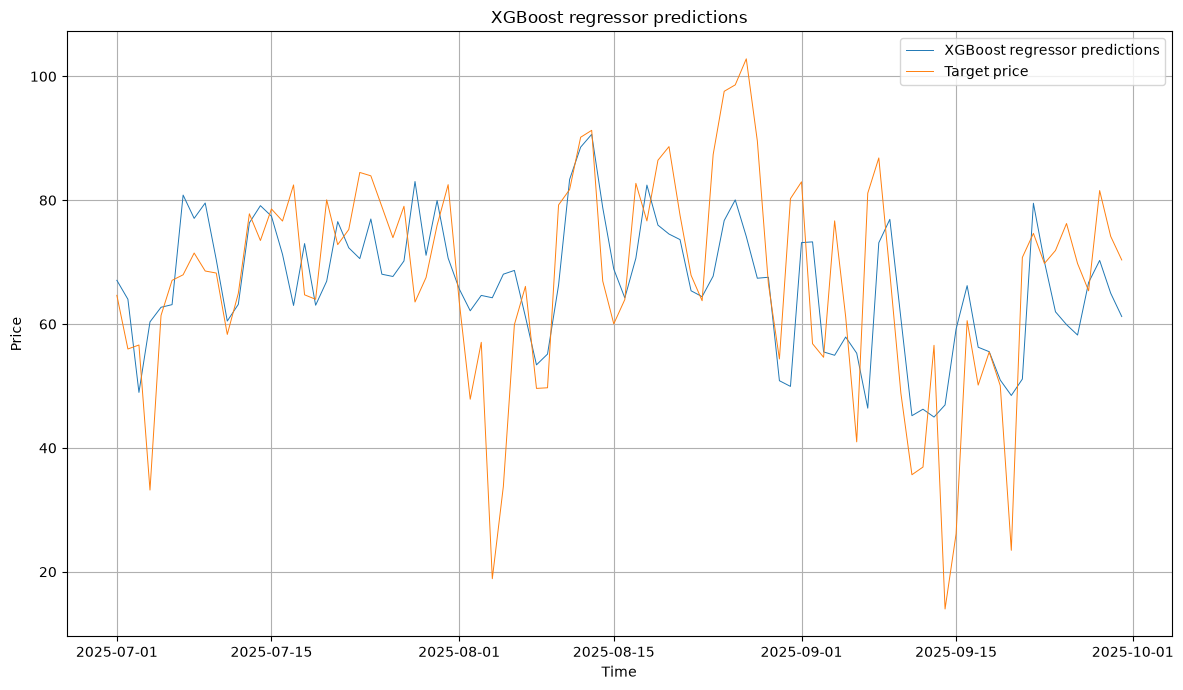

In [60]:
x_data = data.loc[test_data.index, "delivery_day"]
plot_results(x_data=x_data, 
             test_pred=xgb_test_pred, 
             test_targets=test_targets, 
             test_pred_label="XGBoost regressor predictions", 
             test_target_label="Target price", 
             title="XGBoost regressor predictions", 
             y_label="Price")


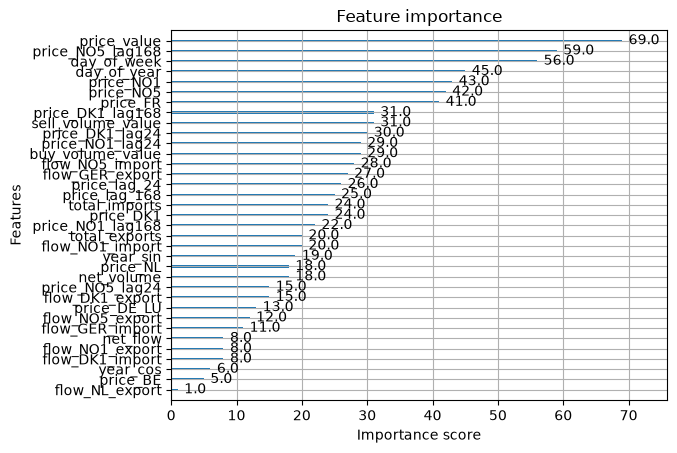

In [61]:
plot_importance(xgb_model)
plt.show()

## Bar chart comparison

In [62]:
results = {"xgb" : xgb_test_scores, "dummy" : dummy_test_scores, "rf" : rf_test_scores}

res_lstm = {'lstm':{'R2': 0.2235, 'RMSE': 36.5655, 'MSE': 1337.0382}}

results= results | res_lstm

In [63]:
metrics = ["RMSE", "MSE", "R2"]
models = list(results.keys())

colors = {
    "xgb": "tab:red",
    "rf": "tab:green",
    "dummy": "tab:blue",
    "lstm": "tab:orange",
}

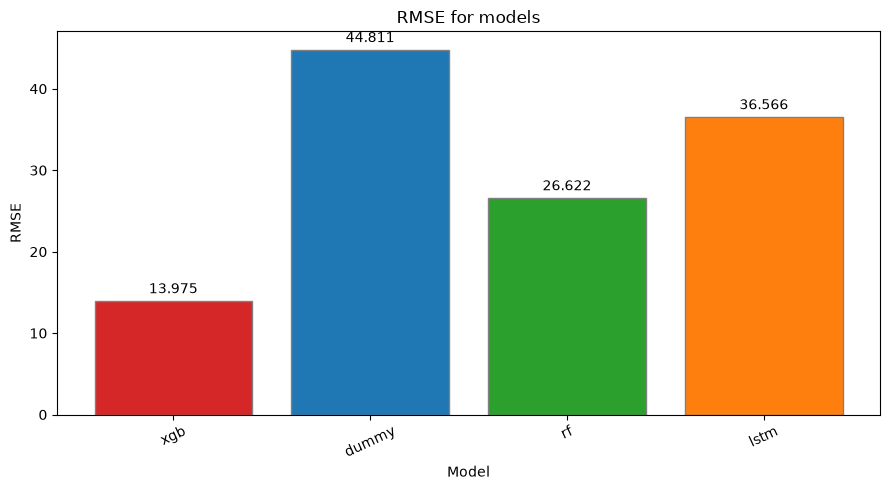

In [64]:
# RMSE
rmse_scores = [results[model]["RMSE"] for model in models]
rmse_colors = [colors[model] for model in models]

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(models, rmse_scores, color=rmse_colors, edgecolor="grey")
ax.set_title("RMSE for models")
ax.set_xlabel("Model")
ax.set_ylabel("RMSE")
ax.tick_params(axis="x", rotation=25)
ax.bar_label(bars, fmt="%.3f", padding=3)
fig.tight_layout()
plt.show()

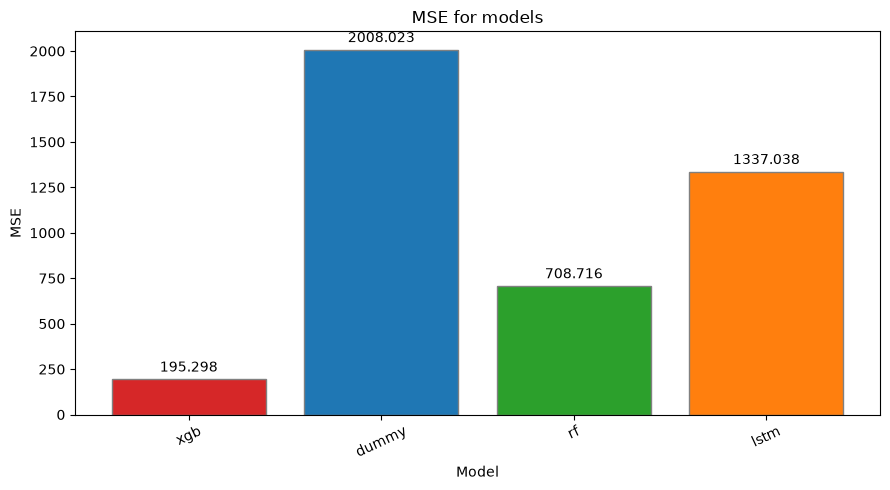

In [65]:
# MSE
mse_scores = [results[model]["MSE"] for model in models]
mse_colors = [colors[model] for model in models]

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(models, mse_scores, color=mse_colors, edgecolor="grey")
ax.set_title("MSE for models")
ax.set_xlabel("Model")
ax.set_ylabel("MSE")
ax.tick_params(axis="x", rotation=25)
ax.bar_label(bars, fmt="%.3f", padding=3)
fig.tight_layout()
plt.show()

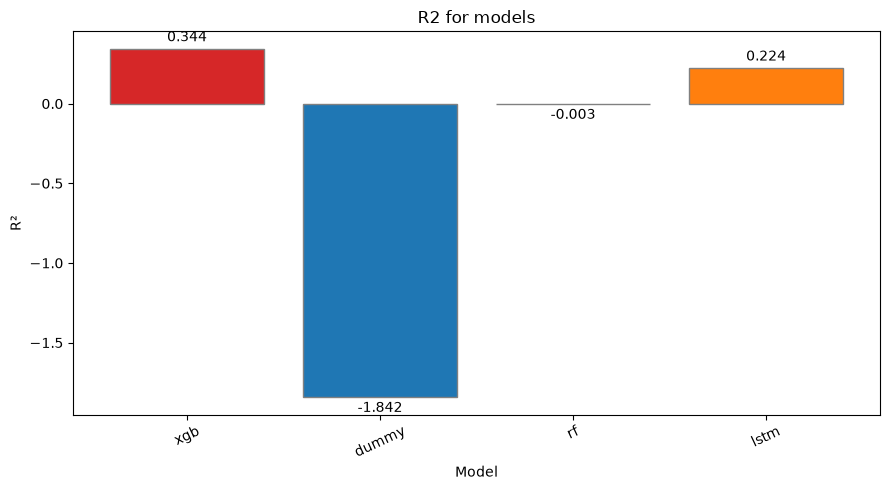

In [66]:
# R2
r2_scores = [results[model]["R2"] for model in models]
r2_colors = [colors[model] for model in models]

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(models, r2_scores, color=r2_colors, edgecolor="grey")
ax.set_title("R2 for models")
ax.set_xlabel("Model")
ax.set_ylabel("R²")
ax.tick_params(axis="x", rotation=25)
ax.bar_label(bars, fmt="%.3f", padding=3)
fig.tight_layout()
plt.show()